# TUGAS KECERDASAN ARTIFISIAL UNTUK GEOFISIKA

## Perancangan Prompt AI untuk Pengolahan dan Interpretasi Data Geolistrik

### Menggunakan Struktur R–T–C–I–K–O–Q–V

#### **Nama:** **Aleksander**
#### **NIM:** *(*H061251003*)*
#### **Mata Kuliah:** Kecerdasan Artifisial untuk Geofisika 
#### **Departemen Geofisika** 
#### **Universitas Hasanuddin**

------------------------------------------------------------------------

## Struktur Prompt

Prompt disusun sebagai *work specification* (spesifikasi pekerjaan),
bukan sekadar pertanyaan. Setiap komponen dipakai untuk mengurangi
ambiguitas agar hasil AI dapat diperiksa, bukan hanya terlihat
meyakinkan.

| Komponen         | Simbol | Fungsi                                                                                                      |
|------------------------|------------------------|------------------------|
| Role             | **R**  | Sudut pandang kerja AI; menentukan istilah dan prioritas, bukan bukti kredensial                            |
| Task             | **T**  | Aksi utama dan hasil yang diminta, memakai kata kerja yang dapat diperiksa (hitung, bandingkan, inversikan) |
| Context          | **C**  | Tujuan penggunaan hasil dan batas tafsirnya                                                                 |
| Input            | **I**  | Data yang boleh dipakai, lengkap dengan format, satuan, dan konfigurasi elektroda                           |
| Constraints      | **K**  | Batasan yang dapat diuji pada prosedur atau hasil                                                           |
| Output           | **O**  | Bentuk, isi, dan nama berkas hasil                                                                          |
| Quality Criteria | **Q**  | Kriteria layak pakai yang terukur, bukan kata umum seperti “akurat”                                         |
| Verification     | **V**  | Pemeriksaan yang dapat dijalankan, beserta kondisi yang diharapkan dan tindakan bila gagal                  |

Bagian yang perlu diisi sebelum prompt dipakai ditulis dalam tanda
kurung siku, misalnya `[NAMA_FILE]`.

## Daftar Prompt

Kelima prompt mengikuti alur kerja data geolistrik dari awal sampai
akhir.

1.  Pemeriksaan Kualitas Data dan Perhitungan Resistivitas Semu
2.  Interpretasi Sounding Satu Dimensi (VES) Konfigurasi Schlumberger
3.  Inversi Dua Dimensi (ERT) dan Pembacaan Penampang Resistivitas
4.  Interpretasi Litologi dan Zona Air Tanah dengan Data Bor
5.  Analisis Ekuivalensi dan Ketidakpastian Model (Parameter Dar
    Zarrouk)

------------------------------------------------------------------------

# Prompt 1 — Pemeriksaan Kualitas Data dan Perhitungan Resistivitas Semu

``` markdown
# R — Role
Anda berperan sebagai ahli metode geolistrik yang membimbing mahasiswa S1 Geofisika dalam memeriksa kualitas data lapangan dan menghitung resistivitas semu.

# T — Task
Periksa kualitas data pengukuran geolistrik, hitung faktor geometri (K) dan resistivitas semu (ρa) untuk setiap titik ukur, lalu tandai data yang mencurigakan.

# C — Context
Pemeriksaan ini adalah tahap awal sebelum pemodelan atau inversi pada praktikum Metode Geolistrik. Hasil hanya dipakai untuk menilai kualitas dan kelayakan data. Interpretasi geologi bukan bagian dari tugas ini.

# I — Input
- Berkas [NAMA_FILE], format [CSV/XLSX/TXT], berisi posisi elektroda arus (A, B) dan potensial (M, N) dalam meter, arus I (mA), beda potensial ΔV (mV), dan bila ada pengukuran ulang atau resiprokal.
- Konfigurasi elektroda: [Wenner / Schlumberger / dipole-dipole / lainnya].
- Rumus (ρa dalam Ω·m, K dalam m, ΔV dalam V, I dalam A):
  - ρa = K · ΔV / I
  - Wenner: K = 2π·a
  - Schlumberger: K = π · ((AB/2)² − (MN/2)²) / MN
  - Dipole-dipole: K = π · n · (n+1) · (n+2) · a
- Gunakan hanya data ini.

# K — Constraints
- Jangan mengubah data asli. Konversi satuan (mA ke A, mV ke V) dilakukan pada kolom baru dan dijelaskan.
- Jangan menghapus data yang mencurigakan. Beri flag beserta alasannya.
- Jelaskan cara mendeteksi data buruk, misalnya ρa negatif, arus terlalu kecil, ΔV di bawah batas kepekaan alat, atau selisih pengukuran ulang yang besar. Nyatakan ambang yang dipakai.
- Jangan menghitung kedalaman investigasi sebagai kedalaman sebenarnya. Bila disebut, jelaskan sebagai perkiraan.
- Jangan membuat interpretasi litologi.

# O — Output
1. Berkas `resistivitas_semu.csv` dengan kolom: posisi elektroda, konfigurasi, I (A), ΔV (V), K (m), ρa (Ω·m), dan kolom `flag` beserta alasannya.
2. Ringkasan jumlah data total, jumlah data ter-flag, dan rentang nilai ρa (minimum, maksimum, median).
3. Gambar ρa terhadap jarak elektroda (atau pseudosection untuk data 2D) dengan data ter-flag diberi tanda berbeda.
4. Penjelasan singkat mengapa kualitas data penting sebelum inversi, dalam bentuk paragraf.
5. Kode Python beserta versi paket yang dipakai.

# Q — Quality Criteria
- Jumlah baris output sama dengan jumlah baris input.
- Semua satuan konsisten dan tercantum pada tiap kolom.
- Setiap flag memiliki alasan dan ambang yang dapat ditelusuri.
- Tidak ada nilai ρa yang tidak berhingga atau kosong tanpa penjelasan.
- Sumbu gambar berlabel satuan dan berskala logaritmik untuk ρa.

# V — Verification
- Hitung ulang satu titik ukur secara manual dan bandingkan dengan hasil program (selisih relatif < 1e-6).
- Uji rumus K dengan kasus sederhana: Wenner dengan a = 10 m harus memberi K = 62,83 m.
- Periksa bahwa jumlah data ter-flag ditambah data tidak ter-flag sama dengan jumlah data total.
- Bila ada pemeriksaan yang gagal, hentikan dan laporkan penyebabnya sebelum membuat gambar akhir.
```

------------------------------------------------------------------------

# Prompt 2 — Interpretasi Sounding Satu Dimensi (VES) Konfigurasi Schlumberger

``` markdown
# R — Role
Anda berperan sebagai ahli geolistrik dan pemodelan satu dimensi yang membimbing mahasiswa S1 Geofisika dalam menginterpretasikan kurva sounding.

# T — Task
Interpretasikan kurva ρa terhadap AB/2 dari data VES untuk menentukan jumlah lapisan, resistivitas sebenarnya (ρ), dan ketebalan (h) tiap lapisan, serta tentukan tipe kurvanya.

# C — Context
VES dipakai pada praktikum Metode Geolistrik untuk memperkirakan struktur berlapis bawah permukaan, misalnya lapisan penutup, lapisan pembawa air, dan batuan dasar. Hasil dipakai sebagai model perkiraan untuk laporan praktikum, bukan penentuan litologi pasti.

# I — Input
- Berkas [NAMA_FILE] berisi AB/2 (m), MN/2 (m), dan ρa (Ω·m) untuk [___] titik sounding.
- Perhatikan pergantian MN pada kurva dan penyambungan segmennya.
- Gunakan hanya data ini. Jangan memakai data lain kecuali data bor yang diberikan secara terpisah [ada/tidak ada].

# K — Constraints
- Jangan mengubah data asli. Bila segmen MN yang berbeda disambung atau digeser, jelaskan caranya.
- Jelaskan alasan pemilihan jumlah lapisan. Jangan menambah lapisan hanya untuk memperkecil galat. Bandingkan minimal dua model dengan jumlah lapisan berbeda.
- Nyatakan metode yang dipakai (pencocokan kurva, inversi kuadrat terkecil, atau lainnya), model awal, dan batas nilai parameter.
- Nyatakan tipe kurva (H, K, A, Q untuk tiga lapisan atau kombinasinya) dan dasar penentuannya.
- Jangan menyimpulkan jenis batuan hanya dari nilai resistivitas. Interpretasi litologi hanya boleh diajukan sebagai dugaan yang dijelaskan dasarnya.
- Jelaskan bahwa solusi inversi tidak unik.

# O — Output
1. Berkas `model_ves.csv`: nomor lapisan, ρ (Ω·m), h (m), kedalaman dasar lapisan (m), dan galat model.
2. Gambar kurva data dan kurva model pada sumbu log–log, serta penampang model berlapis.
3. Tabel perbandingan model dengan jumlah lapisan berbeda beserta galatnya (RMS error, %).
4. Interpretasi dalam bentuk paragraf yang memisahkan hasil hitungan dari dugaan geologi.
5. Keterbatasan hasil, kesimpulan singkat, dan kode Python.

# Q — Quality Criteria
- Galat model dinyatakan dengan angka (RMS error dalam %), bukan hanya "cocok".
- Jumlah lapisan mempunyai alasan yang jelas dan tidak berlebihan terhadap jumlah data.
- Semua satuan konsisten dan tiap parameter mempunyai nilai serta satuan.
- Interpretasi tidak melampaui apa yang didukung data dan dapat dipakai langsung dalam laporan praktikum.

# V — Verification
- Hitung kurva ρa maju (forward) dari model hasil inversi, lalu bandingkan dengan data. Galatnya harus sama dengan yang dilaporkan.
- Ubah model awal (resistivitas dan tebal awal) dan ulangi inversi. Bila hasilnya berubah besar, laporkan bahwa solusi bergantung pada model awal.
- Periksa bahwa kedalaman lapisan terdalam wajar terhadap AB/2 maksimum, dan tandai lapisan yang berada di luar jangkauan data.
- Bila ada pemeriksaan yang gagal, hentikan dan laporkan sebelum menyusun interpretasi.
```

------------------------------------------------------------------------

# Prompt 3 — Inversi Dua Dimensi (ERT) dan Pembacaan Penampang Resistivitas

``` markdown
# R — Role
Anda berperan sebagai ahli Electrical Resistivity Tomography (ERT) dan inversi geofisika yang membimbing mahasiswa S1 Geofisika dalam mengolah dan membaca penampang resistivitas 2D.

# T — Task
Lakukan inversi 2D data ERT untuk memperoleh penampang resistivitas sebenarnya, evaluasi kualitas inversi dengan galat RMS, lalu jelaskan pola resistivitas tinggi dan rendah pada penampang.

# C — Context
ERT dipakai pada praktikum Metode Geolistrik untuk melihat variasi resistivitas secara lateral dan vertikal, misalnya perubahan material atau zona jenuh air. Hasil dipakai untuk interpretasi awal dalam laporan praktikum, bukan keputusan teknis final.

# I — Input
- Berkas [NAMA_FILE] berisi posisi elektroda (m), ρa (Ω·m), konfigurasi [Wenner / Wenner-Schlumberger / dipole-dipole], spasi elektroda [___ m], dan jumlah elektroda [___].
- Data topografi lintasan [ada/tidak ada]. Bila ada, sebutkan format dan satuannya.
- Perangkat lunak atau pustaka inversi yang dipakai: [Res2DInv / pyGIMLi / lainnya].

# K — Constraints
- Jangan mengubah data asli. Data buruk yang dikeluarkan sebelum inversi harus dicatat jumlah, posisi, dan alasannya.
- Nyatakan parameter inversi: jenis regularisasi (misalnya smoothness-constrained L2 atau robust L1), faktor redaman, model awal, dan kriteria berhenti.
- Jangan menghentikan iterasi hanya karena RMS kecil. Jelaskan kewajarannya terhadap kualitas data dan jumlah iterasi.
- Sertakan topografi bila datanya ada. Bila tidak ada, nyatakan asumsi permukaan datar.
- Jangan menafsirkan zona di bagian tepi dan dasar penampang yang tidak dicakup data seolah-olah sama andalnya.
- Jangan menyimpulkan litologi hanya dari warna atau nilai resistivitas.

# O — Output
1. Penampang hasil inversi (jarak terhadap kedalaman) dengan skala warna logaritmik, satuan Ω·m, dan sumbu berlabel.
2. Tabel RMS error tiap iterasi dan RMS akhir (%).
3. Perbandingan tiga penampang: data ρa terukur, ρa hasil perhitungan model, dan model resistivitas sebenarnya.
4. Deskripsi pola resistivitas (zona tinggi, rendah, dan batasnya) dalam bentuk paragraf, lalu dugaan geologi yang dijelaskan dasarnya.
5. Keterbatasan hasil dan kode atau langkah kerja perangkat lunak yang dipakai.

# Q — Quality Criteria
- RMS akhir dilaporkan dengan angka dan dinilai terhadap kualitas data, bukan hanya "bagus".
- Skala warna, kedalaman, dan sumbu tercantum dan tidak dipotong tanpa penanda.
- Deskripsi pola dipisahkan dari dugaan geologi.
- Penjelasan dapat diikuti mahasiswa S1 dan dapat dipakai langsung dalam laporan.

# V — Verification
- Bandingkan penampang ρa terukur dengan ρa hasil perhitungan model. Pola umumnya harus mirip dan selisih besar harus dijelaskan.
- Ulangi inversi dengan faktor redaman berbeda. Bila struktur utama berubah besar, laporkan bahwa struktur tersebut tidak stabil.
- Periksa bahwa perubahan RMS antar iterasi melandai. Bila terus turun tajam, laporkan bahwa inversi belum konvergen.
- Bila ada pemeriksaan yang gagal, hentikan dan laporkan sebelum menyusun interpretasi.
```

------------------------------------------------------------------------

# Prompt 4 — Interpretasi Litologi dan Zona Air Tanah dengan Data Bor

``` markdown
# R — Role
Anda berperan sebagai ahli geofisika dan hidrogeologi yang membimbing mahasiswa S1 Geofisika dalam menghubungkan nilai resistivitas dengan litologi dan keberadaan air tanah.

# T — Task
Bandingkan nilai resistivitas hasil pemodelan dengan data bor, kelompokkan lapisan ke dalam kelas resistivitas, lalu tentukan lapisan yang berpotensi menjadi akuifer beserta tingkat keyakinannya.

# C — Context
Analisis dilakukan pada praktikum Metode Geolistrik dan Hidrogeofisika. Nilai resistivitas dipengaruhi oleh litologi, porositas, kandungan lempung, dan kualitas air, sehingga satu nilai resistivitas dapat berasal dari lebih dari satu kemungkinan. Hasil dipakai sebagai interpretasi awal, bukan penentuan potensi air tanah final.

# I — Input
- Model resistivitas hasil VES atau ERT: [NAMA_FILE] berisi kedalaman (m) dan ρ (Ω·m).
- Data bor atau sumur terdekat: [NAMA_FILE] berisi kedalaman (m), deskripsi litologi, dan muka air tanah (m) bila ada. Jarak titik bor dari lintasan ukur [___ m].
- Tabel rentang resistivitas acuan: [sumber acuan yang dipakai].
- Gunakan hanya data ini.

# K — Constraints
- Jangan mengubah nilai resistivitas hasil pemodelan.
- Sebutkan sumber tabel rentang resistivitas. Jangan memakai satu rentang universal karena rentang antarjenis material saling tumpang tindih.
- Jelaskan ketidakpastian akibat perbedaan skala (resolusi geolistrik terhadap deskripsi bor) dan jarak titik bor dari lintasan.
- Jangan menyimpulkan akuifer produktif hanya dari nilai resistivitas. Lempung jenuh air asin dan batuan kompak sama-sama dapat menghasilkan resistivitas rendah atau tinggi yang menyesatkan.
- Bila relasi Archie (ρ = a · ρw · φ^−m · Sw^−n) dipakai, nyatakan semua parameternya dan sumbernya. Jangan menebak nilai porositas.
- Jangan membuat perkiraan debit atau kualitas air.

# O — Output
1. Tabel korelasi kedalaman: lapisan resistivitas, litologi bor, dan tingkat kecocokan (sesuai / sebagian / tidak sesuai) beserta alasannya.
2. Tabel kelas resistivitas dengan dugaan material dan tingkat keyakinan (tinggi / sedang / rendah).
3. Gambar model resistivitas berdampingan dengan kolom litologi bor pada skala kedalaman yang sama.
4. Interpretasi dalam bentuk paragraf tentang lapisan yang berpotensi menjadi akuifer, disertai alternatif tafsir lain.
5. Keterbatasan dan kesimpulan singkat.

# Q — Quality Criteria
- Setiap dugaan litologi mempunyai dasar yang dapat ditelusuri ke data bor atau ke tabel acuan yang disebut.
- Tingkat keyakinan dinyatakan eksplisit dan tidak seragam untuk semua lapisan.
- Alternatif tafsir dicantumkan untuk lapisan yang ambigu.
- Kedalaman dan satuan konsisten pada seluruh tabel dan gambar.

# V — Verification
- Periksa bahwa kedalaman batas lapisan geolistrik dan batas litologi bor dibandingkan pada satuan dan datum yang sama.
- Periksa apakah kedalaman muka air tanah dari data bor konsisten dengan penurunan resistivitas pada model. Bila tidak, jelaskan kemungkinan penyebabnya.
- Untuk tiap lapisan yang dinilai berpotensi akuifer, sebutkan minimal satu bukti yang dapat menyangkalnya, lalu nilai apakah bukti itu terbantahkan oleh data.
- Bila ada pemeriksaan yang gagal, turunkan tingkat keyakinan lapisan tersebut dan laporkan alasannya.
```

------------------------------------------------------------------------

# Prompt 5 — Analisis Ekuivalensi dan Ketidakpastian Model (Parameter Dar Zarrouk)

``` markdown
# R — Role
Anda berperan sebagai peninjau metode inversi geolistrik yang membimbing mahasiswa S1 Geofisika dalam menilai seberapa andal model hasil interpretasi.

# T — Task
Hitung parameter Dar Zarrouk (konduktansi longitudinal S dan resistansi transversal T), lalu uji prinsip ekuivalensi untuk menunjukkan rentang model yang sama-sama cocok dengan data VES.

# C — Context
Pada VES, beberapa kombinasi ketebalan dan resistivitas dapat menghasilkan kurva ρa yang hampir sama (prinsip ekuivalensi). Analisis dilakukan pada praktikum Metode Geolistrik untuk memahami bahwa hasil pemodelan mempunyai ketidakpastian. Hasil dipakai untuk menyatakan rentang parameter yang wajar, bukan nilai tunggal.

# I — Input
- Model VES hasil interpretasi [NAMA_FILE]: ρ (Ω·m) dan h (m) tiap lapisan.
- Data VES asli [NAMA_FILE]: AB/2 (m) dan ρa (Ω·m).
- Batas toleransi galat yang dianggap masih cocok dengan data: [misalnya RMS error ≤ ___ %].
- Rumus:
  - S = Σ (hᵢ / ρᵢ), dalam siemens (S)
  - T = Σ (hᵢ · ρᵢ), dalam Ω·m²
- Gunakan hanya data ini.

# K — Constraints
- Jangan mengubah model dan data asli. Semua variasi model dibuat pada salinan.
- Nyatakan lapisan yang diuji ekuivalensinya dan alasannya: lapisan konduktif diuji terhadap S konstan, lapisan resistif diuji terhadap T konstan.
- Nyatakan cara membuat variasi model (rentang perubahan ρ dan h, jumlah model yang diuji) dan kriteria diterimanya sebuah model.
- Jangan menyatakan satu model sebagai "benar". Laporkan rentang parameter yang memenuhi toleransi.
- Jelaskan keterbatasan bila jumlah data kecil atau sebaran AB/2 sempit.

# O — Output
1. Tabel S dan T tiap lapisan dan total, beserta satuannya.
2. Berkas `model_ekuivalen.csv` berisi model-model yang memenuhi toleransi: ρ, h, S atau T, dan RMS error.
3. Gambar: (a) kurva data dan beberapa kurva model ekuivalen, (b) rentang ρ dan h yang diterima untuk lapisan yang diuji.
4. Interpretasi dalam bentuk paragraf tentang parameter yang tertentu dengan baik dan yang tidak, serta dampaknya pada interpretasi geologi.
5. Keterbatasan, kesimpulan singkat, dan kode Python.

# Q — Quality Criteria
- Rentang parameter dilaporkan dengan angka dan satuan, tidak hanya nilai tunggal.
- Setiap model ekuivalen memenuhi toleransi galat yang dinyatakan.
- Penjelasan ekuivalensi benar secara fisis dan mudah dipahami mahasiswa S1.
- Kesimpulan menyatakan parameter mana yang andal dan mana yang tidak.

# V — Verification
- Periksa bahwa S (untuk uji lapisan konduktif) atau T (untuk uji lapisan resistif) pada model ekuivalen tetap sama dengan model awal (selisih relatif < 1%).
- Hitung kurva ρa maju dari tiap model ekuivalen dan pastikan RMS error-nya sesuai yang dilaporkan.
- Bandingkan rentang yang diperoleh dengan hasil dua model dengan jumlah lapisan berbeda dari Prompt 2. Laporkan bila ada perbedaan besar.
- Bila ada pemeriksaan yang gagal, hentikan dan laporkan sebelum membuat kesimpulan.
```

------------------------------------------------------------------------

## Catatan Penyusunan

-   Kelima prompt mengikuti alur data geolistrik: pemeriksaan data,
    pemodelan 1D, inversi 2D, korelasi dengan data bor, lalu penilaian
    ketidakpastian.
-   Seluruh prompt memisahkan hasil hitungan dari interpretasi dan
    membatasi klaim sesuai data yang tersedia.
-   Setiap prompt memuat pemeriksaan yang dapat dijalankan beserta
    tindakan bila pemeriksaan gagal.
-   Bagian dalam tanda kurung siku `[ ]` diisi sesuai data geolistrik
    praktikum sebelum prompt dikirim ke AI.

---

# BAGIAN LANJUTAN: IMPLEMENTASI KODE PYTHON UNTUK 5 PROMPT GEOLISTRIK

**Catatan penting:** semua kode di bagian ini dijalankan pada **data sintetis** (dibangkitkan oleh kode) agar alur kerja tiap prompt dapat dijalankan dan dipahami. Angka yang keluar **bukan hasil pengukuran lapangan** dan tidak boleh dilaporkan sebagai hasil survei. Bila data asli tersedia, ganti bagian pembuatan data dengan `pd.read_csv(...)` berkas data Anda.

Kode hanya memakai `numpy`, `scipy`, `pandas`, dan `matplotlib` (sudah tersedia di Google Colab), sehingga **tidak perlu memasang paket tambahan**. Jalankan sel dari atas ke bawah.

| Bagian | Prompt | Isi kode | Berkas keluaran |
|---|---|---|---|
| 0 | – | Pustaka, fungsi bantu, fungsi pemodelan maju (forward) VES, data lapangan sintetis | `data_lapangan_sintetis.csv` |
| 1 | Prompt 1 | Faktor geometri K, ρa, penandaan data buruk, pemeriksaan | `resistivitas_semu.csv` |
| 2 | Prompt 2 | Inversi VES 1D, perbandingan 2/3/4 lapisan, tipe kurva | `model_ves.csv` |
| 3 | Prompt 3 | Inversi ERT 2D (forward 2.5D + Gauss-Newton smoothness-constrained) | – |
| 4 | Prompt 4 | Korelasi dengan data bor, kelas resistivitas, kandidat akuifer | – |
| 5 | Prompt 5 | Parameter Dar Zarrouk dan uji ekuivalensi | `model_ekuivalen.csv` |

Alur data: Prompt 1 → Prompt 2 → Prompt 4 → Prompt 5. Prompt 3 berdiri sendiri (data ERT sintetis).

## 0. Persiapan: pustaka, fungsi bantu, dan fungsi pemodelan maju (forward)

Fungsi `schlum_forward` menghitung kurva ρa untuk model berlapis horizontal pada konfigurasi Schlumberger memakai transformasi Hankel:

$$
\rho_a(s)=\rho_1 + s^2\int_0^\infty \big[T(\lambda)-\rho_1\big]\,J_1(\lambda s)\,\lambda\,d\lambda ,\qquad s=\tfrac{AB}{2}
$$

dengan fungsi transformasi resistivitas $T(\lambda)$ dihitung rekursif dari lapisan terdalam ke atas. Integral dihitung secara numerik (aturan trapesium pada grid λ rapat). Pendekatan elektroda potensial berjarak kecil (MN ≪ AB) dipakai.

In [1]:
# 0. Persiapan: pustaka, fungsi bantu, fungsi forward VES
import sys, os, warnings
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import scipy
from scipy.special import j1
from scipy.optimize import least_squares

warnings.filterwarnings("ignore")
print("Versi paket: python", sys.version.split()[0], "| numpy", np.__version__, "| scipy", scipy.__version__,
      "| pandas", pd.__version__, "| matplotlib", matplotlib.__version__)

rng = np.random.default_rng(2026)          # seed tetap agar hasil dapat diulang
plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": 0.3})
trapz = getattr(np, "trapezoid", None) or np.trapz

# ---------- daftar pemeriksaan (verifikasi) ----------
CHECKS = []
def check(grup, nama, kondisi, detail=""):
    CHECKS.append((grup, nama, bool(kondisi), detail))
    print(("[LULUS] " if kondisi else "[GAGAL] ") + f"{nama}" + (f"  ->  {detail}" if detail else ""))

def semua_lulus(grup):
    return all(ok for g, _, ok, _ in CHECKS if g == grup)

def rms_persen(d_obs, d_cal):
    """RMS galat relatif (%) antara rho_a terukur dan rho_a model."""
    d_obs, d_cal = np.asarray(d_obs, float), np.asarray(d_cal, float)
    return 100*np.sqrt(np.mean(((d_obs - d_cal)/d_obs)**2))

# ---------- faktor geometri (m) ----------
def K_wenner(a):               return 2*np.pi*a
def K_schlumberger(ab2, mn):   return np.pi*(ab2**2 - (mn/2)**2)/mn
def K_dipole(a, n):            return np.pi*n*(n+1)*(n+2)*a

# ---------- forward VES Schlumberger (model berlapis horizontal) ----------
LAM = np.linspace(0.0, 20.0, 40001)        # grid bilangan gelombang lambda (1/m); valid untuk h >= 0.5 m
_J1_CACHE = {}

def _T_kernel(rho, h):
    T = np.full_like(LAM, rho[-1])
    for i in range(len(rho) - 2, -1, -1):
        th = np.tanh(LAM*h[i])
        T = (T + rho[i]*th)/(1.0 + T*th/rho[i])
    return T

def schlum_forward(rho, h, s):
    """rho (Ω·m, n lapisan), h (m, n-1 lapisan), s = AB/2 (m, maks. ~300). Mengembalikan rho_a (Ω·m)."""
    rho, h, s = np.asarray(rho, float), np.asarray(h, float), np.atleast_1d(np.asarray(s, float))
    key = s.tobytes()
    if key not in _J1_CACHE:
        _J1_CACHE[key] = j1(np.outer(LAM, s))
    T = _T_kernel(rho, h)
    integ = trapz((T - rho[0])[:, None]*LAM[:, None]*_J1_CACHE[key], LAM, axis=0)
    return rho[0] + s**2*integ

# ---------- uji mandiri fungsi forward ----------
s_uji = np.array([1.5, 10.0, 100.0, 300.0])
r_homog = schlum_forward([75.0], [], s_uji)
check("P0", "Forward: setengah ruang homogen 75 Ω·m menghasilkan ρa = 75 Ω·m",
      np.allclose(r_homog, 75.0, rtol=1e-9), f"ρa = {np.round(r_homog, 3)}")
r_2l = schlum_forward([10.0, 100.0], [0.5], np.array([0.05, 300.0]))
check("P0", "Forward: dua lapisan (10/100 Ω·m, h = 0,5 m); AB/2 sangat kecil → ρ1 dan AB/2 besar → ρ2",
      abs(r_2l[0]/10 - 1) < 0.02 and abs(r_2l[1]/100 - 1) < 0.05,
      f"ρa(0,05 m) = {r_2l[0]:.2f}; ρa(300 m) = {r_2l[1]:.2f} Ω·m")
r_3same = schlum_forward([40.0, 40.0, 40.0], [3.0, 7.0], s_uji)
check("P0", "Forward: tiga lapisan dengan ρ sama harus memberi ρa konstan", np.allclose(r_3same, 40.0, rtol=1e-6),
      f"ρa = {np.round(r_3same, 3)}")
assert semua_lulus("P0"), "Uji fungsi forward gagal - hentikan dan periksa fungsi."

Versi paket: python 3.13.16 | numpy 2.5.3 | scipy 1.18.1 | pandas 3.0.5 | matplotlib 3.11.2
[LULUS] Forward: setengah ruang homogen 75 Ω·m menghasilkan ρa = 75 Ω·m  ->  ρa = [75. 75. 75. 75.]
[LULUS] Forward: dua lapisan (10/100 Ω·m, h = 0,5 m); AB/2 sangat kecil → ρ1 dan AB/2 besar → ρ2  ->  ρa(0,05 m) = 10.00; ρa(300 m) = 99.92 Ω·m
[LULUS] Forward: tiga lapisan dengan ρ sama harus memberi ρa konstan  ->  ρa = [40. 40. 40. 40.]


### Data lapangan sintetis (sebagai pengganti berkas pengukuran)

Sebuah model bumi berlapis **dipilih penulis hanya untuk membangkitkan data**, lalu diberi noise dan beberapa cacat pengukuran yang disengaja (arus terlalu kecil, ΔV terlalu kecil, tanda ΔV terbalik, dan selisih pengukuran ulang antar-MN). Model ini **tidak dipakai** sebagai masukan inversi. Pergantian MN dilakukan pada AB/2 = 10 m dan 40 m, dengan pengukuran *overlap* (kedua MN diukur) di titik pergantian.

In [2]:
# ---- Pembangkitan data lapangan sintetis (Schlumberger) ----
RHO_TRUE = np.array([120.0, 18.0, 60.0, 400.0])   # Ω·m  (HANYA untuk membangkitkan data)
H_TRUE   = np.array([2.0, 6.0, 18.0])             # m    (lapisan ke-4 = setengah ruang)

ab2_list = np.array([1.5, 2, 3, 4, 6, 8, 10, 15, 20, 30, 40, 60, 80, 100, 150, 200, 300], float)
def mn_untuk(ab2):
    return 0.5 if ab2 <= 10 else (2.0 if ab2 <= 40 else 10.0)
def arus_mA(ab2):
    return 100.0 if ab2 <= 10 else (200.0 if ab2 <= 40 else 500.0)

baris = []
for s in ab2_list:
    daftar_mn = [mn_untuk(s)]
    if s in (10.0, 40.0):                       # titik pergantian MN: ukur kedua MN (overlap)
        daftar_mn = [0.5, 2.0] if s == 10.0 else [2.0, 10.0]
    for mn in daftar_mn:
        baris.append({"AB/2 (m)": s, "MN (m)": mn, "A (m)": -s, "B (m)": s,
                      "M (m)": -mn/2, "N (m)": mn/2, "I (mA)": arus_mA(s)})
raw = pd.DataFrame(baris)

rho_a_benar = schlum_forward(RHO_TRUE, H_TRUE, raw["AB/2 (m)"].values)
K_raw = K_schlumberger(raw["AB/2 (m)"].values, raw["MN (m)"].values)
noise = 1 + rng.normal(0, 0.02, len(raw))                     # noise acak 2 %
raw["dV (mV)"] = rho_a_benar*(raw["I (mA)"].values/1000)/K_raw*noise*1000

# ---- cacat pengukuran yang disengaja (untuk menguji prosedur QC) ----
def idx(ab2, mn):
    return raw.index[(raw["AB/2 (m)"] == ab2) & (raw["MN (m)"] == mn)][0]
raw.loc[idx(4.0, 0.5), "dV (mV)"] *= -0.2        # tanda ΔV terbalik (pickup/kabel tertukar)
raw.loc[idx(100.0, 10.0), "I (mA)"] = 6.0        # arus terlalu kecil
raw.loc[idx(100.0, 10.0), "dV (mV)"] = rho_a_benar[idx(100.0, 10.0)]*0.006/K_raw[idx(100.0, 10.0)]*1000
raw.loc[idx(300.0, 10.0), "I (mA)"] = 20.0       # ΔV akan sangat kecil
raw.loc[idx(300.0, 10.0), "dV (mV)"] = rho_a_benar[idx(300.0, 10.0)]*0.020/K_raw[idx(300.0, 10.0)]*1000
raw.loc[idx(40.0, 10.0), "dV (mV)"] *= 1.18      # overlap MN tidak konsisten (kontak elektroda buruk)

raw.insert(0, "No", np.arange(1, len(raw) + 1))
raw.to_csv("data_lapangan_sintetis.csv", index=False)
print(f"Data lapangan sintetis disimpan: data_lapangan_sintetis.csv ({len(raw)} baris)")
display(raw.round(3).head(8))

Data lapangan sintetis disimpan: data_lapangan_sintetis.csv (19 baris)


,No,AB/2 (m),MN (m),A (m),B (m),M (m),N (m),I (mA),dV (mV)
0,1,1.5,0.5,-1.5,1.5,-0.25,0.25,100.0,809.313
1,2,2.0,0.5,-2.0,2.0,-0.25,0.25,100.0,429.471
2,3,3.0,0.5,-3.0,3.0,-0.25,0.25,100.0,148.243
3,4,4.0,0.5,-4.0,4.0,-0.25,0.25,100.0,-13.796
4,5,6.0,0.5,-6.0,6.0,-0.25,0.25,100.0,18.495
5,6,8.0,0.5,-8.0,8.0,-0.25,0.25,100.0,7.566
6,7,10.0,0.5,-10.0,10.0,-0.25,0.25,100.0,4.376
7,8,10.0,2.0,-10.0,10.0,-1.00,1.00,100.0,17.889


---

# Prompt 1 — Pemeriksaan Kualitas Data dan Perhitungan Resistivitas Semu

Kode berikut menjalankan spesifikasi Prompt 1: membaca data tanpa mengubahnya, mengonversi satuan pada **kolom baru**, menghitung K dan ρa, **menandai (bukan menghapus)** data mencurigakan beserta alasan dan ambangnya, lalu menjalankan pemeriksaan V sebelum gambar akhir dibuat.

Ambang yang dipakai (dapat diubah sesuai alat dan lokasi):

| Aturan flag | Ambang |
|---|---|
| ρa tidak positif | ρa ≤ 0 |
| Arus terlalu kecil | I < 10 mA |
| ΔV di bawah batas kepekaan | ΔV < 1 mV |
| Selisih pengukuran *overlap* antar-MN pada AB/2 yang sama | > 10 % |

In [3]:
# ---- Prompt 1: QC data dan perhitungan resistivitas semu ----
I_MIN_mA, DV_MIN_mV, TOL_OVERLAP = 10.0, 1.0, 0.10
df = pd.read_csv("data_lapangan_sintetis.csv")          # data asli TIDAK diubah
n_input = len(df)

out = pd.DataFrame({
    "No": df["No"],
    "Konfigurasi": "Schlumberger",
    "A (m)": df["A (m)"], "B (m)": df["B (m)"], "M (m)": df["M (m)"], "N (m)": df["N (m)"],
    "AB/2 (m)": df["AB/2 (m)"], "MN (m)": df["MN (m)"],
    "I (A)":  df["I (mA)"]/1000.0,          # kolom baru: mA -> A
    "dV (V)": df["dV (mV)"]/1000.0,         # kolom baru: mV -> V
})
out["K (m)"] = K_schlumberger(out["AB/2 (m)"].values, out["MN (m)"].values)
out["rho_a (ohm.m)"] = out["K (m)"]*out["dV (V)"]/out["I (A)"]

alasan = [[] for _ in range(len(out))]
for i, r in out.iterrows():
    if r["rho_a (ohm.m)"] <= 0:                 alasan[i].append("rho_a <= 0 (tanda dV terbalik / noise)")
    if r["I (A)"]*1000 < I_MIN_mA:              alasan[i].append(f"arus < {I_MIN_mA:g} mA")
    if abs(r["dV (V)"])*1000 < DV_MIN_mV:       alasan[i].append(f"|dV| < {DV_MIN_mV:g} mV (di bawah kepekaan alat)")
for ab2, grp in out.groupby("AB/2 (m)"):
    if len(grp) >= 2:
        pos = grp[grp["rho_a (ohm.m)"] > 0]["rho_a (ohm.m)"]
        if len(pos) >= 2 and pos.max()/pos.min() - 1 > TOL_OVERLAP:
            for i in grp.index:
                alasan[i].append(f"selisih overlap antar-MN {100*(pos.max()/pos.min()-1):.0f}% > {100*TOL_OVERLAP:.0f}%")

out["flag"] = [len(a) > 0 for a in alasan]
out["alasan_flag"] = ["; ".join(a) if a else "" for a in alasan]
out.to_csv("resistivitas_semu.csv", index=False)

# ---- Ringkasan ----
rho_valid = out.loc[out["rho_a (ohm.m)"] > 0, "rho_a (ohm.m)"]
print(f"Jumlah data total        : {len(out)}")
print(f"Jumlah data ter-flag     : {int(out['flag'].sum())}")
print(f"Jumlah data tidak ter-flag: {int((~out['flag']).sum())}")
print(f"Rentang ρa (hanya ρa > 0): min = {rho_valid.min():.1f}, maks = {rho_valid.max():.1f}, median = {rho_valid.median():.1f} Ω·m")
display(out.loc[out["flag"], ["No", "AB/2 (m)", "MN (m)", "I (A)", "dV (V)", "rho_a (ohm.m)", "alasan_flag"]].round(5))

Jumlah data total        : 19
Jumlah data ter-flag     : 5
Jumlah data tidak ter-flag: 14
Rentang ρa (hanya ρa > 0): min = 27.5, maks = 233.8, median = 73.2 Ω·m


,No,AB/2 (m),MN (m),I (A),dV (V),rho_a (ohm.m),alasan_flag
3,4,4.0,0.5,0.100,-0.01380,-13.81515,rho_a <= 0 (tanda dV terbalik / noise)
11,12,40.0,2.0,0.200,0.00463,58.11274,selisih overlap antar-MN 17% > 10%
12,13,40.0,10.0,0.200,0.02740,67.78727,selisih overlap antar-MN 17% > 10%
15,16,100.0,10.0,0.006,0.00022,116.69673,arus < 10 mA; |dV| < 1 mV (di bawah kepekaan a...
18,19,300.0,10.0,0.020,0.00017,233.78230,|dV| < 1 mV (di bawah kepekaan alat)


[LULUS] Hitung ulang manual titik ke-8 cocok dengan program (selisih relatif < 1e-6)  ->  selisih = 0.00e+00
[LULUS] K Wenner (a = 10 m) = 62,83 m  ->  K = 62.8319 m
[LULUS] Jumlah baris keluaran = jumlah baris masukan  ->  19 = 19
[LULUS] Data ter-flag + tidak ter-flag = total
[LULUS] Tidak ada ρa kosong atau tak hingga
[LULUS] Setiap flag memiliki alasan


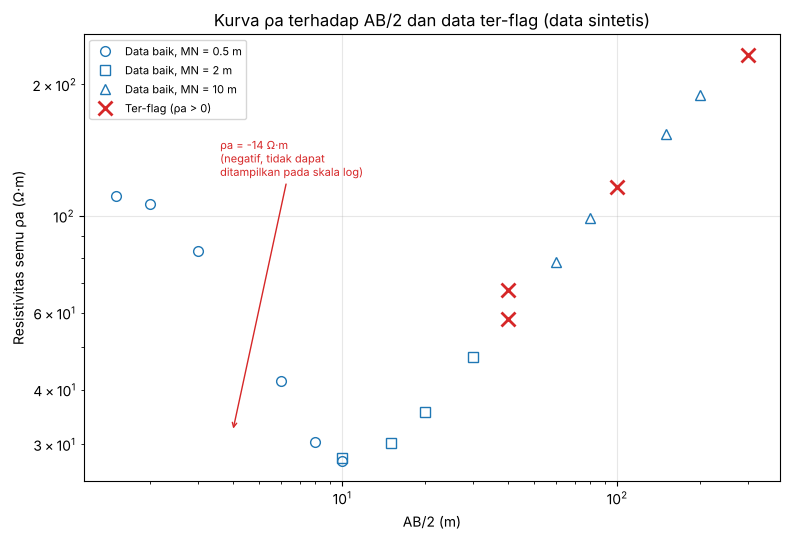

In [4]:
# ---- Prompt 1: Verifikasi (V) sebelum gambar akhir ----
# (1) hitung ulang satu titik secara manual (tanpa fungsi di atas) dan bandingkan
r7 = df.iloc[7]
ab2, mn, I_A, dV_V = r7["AB/2 (m)"], r7["MN (m)"], r7["I (mA)"]/1000, r7["dV (mV)"]/1000
K_manual = 3.141592653589793*((ab2)**2 - (mn/2)**2)/mn
rho_manual = K_manual*dV_V/I_A
selisih = abs(rho_manual - out.loc[7, "rho_a (ohm.m)"])/abs(rho_manual)
check("P1", "Hitung ulang manual titik ke-8 cocok dengan program (selisih relatif < 1e-6)", selisih < 1e-6, f"selisih = {selisih:.2e}")
# (2) uji K Wenner a = 10 m
check("P1", "K Wenner (a = 10 m) = 62,83 m", abs(K_wenner(10.0) - 62.83) < 0.01, f"K = {K_wenner(10.0):.4f} m")
# (3) jumlah baris dan jumlah flag
check("P1", "Jumlah baris keluaran = jumlah baris masukan", len(out) == n_input, f"{len(out)} = {n_input}")
check("P1", "Data ter-flag + tidak ter-flag = total",
      int(out['flag'].sum()) + int((~out['flag']).sum()) == len(out))
# (4) tidak ada nilai kosong / tak hingga tanpa penjelasan
check("P1", "Tidak ada ρa kosong atau tak hingga", np.isfinite(out["rho_a (ohm.m)"]).all())
# (5) setiap flag punya alasan
check("P1", "Setiap flag memiliki alasan", bool((out.loc[out["flag"], "alasan_flag"] != "").all()))
if not semua_lulus("P1"):
    raise RuntimeError("Ada pemeriksaan yang gagal: hentikan dan laporkan penyebabnya sebelum membuat gambar akhir.")

# ---- Gambar: ρa terhadap AB/2 (log-log), data ter-flag diberi tanda berbeda ----
ok = out[~out["flag"]]
bad = out[out["flag"] & (out["rho_a (ohm.m)"] > 0)]
neg = out[out["rho_a (ohm.m)"] <= 0]
fig, ax = plt.subplots(figsize=(8, 5.5))
for mn_val, mk in zip([0.5, 2.0, 10.0], ["o", "s", "^"]):
    sub = ok[ok["MN (m)"] == mn_val]
    ax.loglog(sub["AB/2 (m)"], sub["rho_a (ohm.m)"], mk, ms=7, mfc="none", color="tab:blue", label=f"Data baik, MN = {mn_val:g} m")
ax.loglog(bad["AB/2 (m)"], bad["rho_a (ohm.m)"], "x", ms=10, mew=2, color="tab:red", label="Ter-flag (ρa > 0)")
for _, r in neg.iterrows():
    ax.annotate(f"ρa = {r['rho_a (ohm.m)']:.0f} Ω·m\n(negatif, tidak dapat\nditampilkan pada skala log)",
                xy=(r["AB/2 (m)"], ax.get_ylim()[0]*1.3), xytext=(r["AB/2 (m)"]*0.9, ax.get_ylim()[0]*5),
                fontsize=8, color="tab:red", arrowprops=dict(arrowstyle="->", color="tab:red"))
ax.set_xlabel("AB/2 (m)"); ax.set_ylabel("Resistivitas semu ρa (Ω·m)")
ax.set_title("Kurva ρa terhadap AB/2 dan data ter-flag (data sintetis)")
ax.legend(fontsize=8); plt.tight_layout(); plt.show()

### Mengapa kualitas data penting sebelum inversi

Inversi mencari model yang cocok dengan *semua* data yang diberikan. Satu data buruk, misalnya ρa negatif atau ΔV yang tenggelam dalam noise, tidak dianggap "salah" oleh program; program akan berusaha mencocokkannya dengan membentuk lapisan atau anomali yang sebenarnya tidak ada. Akibatnya, model terlihat meyakinkan padahal strukturnya buatan data buruk. Karena itu data yang mencurigakan **ditandai dan diperiksa** (bukan dihapus diam-diam), dan ambang tiap aturan ditulis jelas agar keputusan membuang atau mempertahankan data dapat ditelusuri. Pada contoh ini, data ter-flag dikeluarkan hanya pada tahap inversi (Prompt 2), sedangkan berkas asli tetap utuh.

---

# Prompt 2 — Interpretasi Sounding Satu Dimensi (VES) Konfigurasi Schlumberger

Kode berikut membaca `resistivitas_semu.csv` dari Prompt 1 (hanya data tidak ter-flag), lalu **menginversikan** kurva ρa dengan **kuadrat terkecil nonlinear** (`scipy.optimize.least_squares`, galat dalam ln ρa, parameter dalam ln ρ dan ln h dengan batas):

- ρ dibatasi 1 – 5000 Ω·m, h dibatasi 0,5 – 150 m (batas bawah 0,5 m juga syarat ketelitian fungsi forward).
- Model 2, 3, dan 4 lapisan dibandingkan. Setiap jumlah lapisan dijalankan dari **6 model awal berbeda**; hasil terbaik dipilih.
- Pemilihan jumlah lapisan memakai kriteria informasi **BIC** (menghukum parameter berlebih) dengan asumsi simpangan baku data 3 %, bukan sekadar galat terkecil.

In [5]:
# ---- Prompt 2: inversi VES 1D ----
d2 = pd.read_csv("resistivitas_semu.csv")
d2 = d2[~d2["flag"]].sort_values("AB/2 (m)")
s_obs = d2["AB/2 (m)"].values.astype(float)
rho_obs = d2["rho_a (ohm.m)"].values.astype(float)
print(f"Data dipakai untuk inversi: {len(s_obs)} dari {len(pd.read_csv('resistivitas_semu.csv'))} titik (data ter-flag dikeluarkan hanya di sini).")

SIGMA = 0.03     # asumsi simpangan baku relatif data (3 %), dipakai untuk BIC
RHO_B, H_B = (1.0, 5000.0), (0.5, 150.0)

def fit_ves(n, rho0, h0):
    lb = np.r_[np.full(n, np.log(RHO_B[0])), np.full(n-1, np.log(H_B[0]))]
    ub = np.r_[np.full(n, np.log(RHO_B[1])), np.full(n-1, np.log(H_B[1]))]
    x0 = np.clip(np.log(np.r_[rho0, h0]), lb + 1e-6, ub - 1e-6)
    def resid(p):
        return np.log(schlum_forward(np.exp(p[:n]), np.exp(p[n:]), s_obs)) - np.log(rho_obs)
    r = least_squares(resid, x0, bounds=(lb, ub))
    rho, h = np.exp(r.x[:n]), np.exp(r.x[n:])
    cal = schlum_forward(rho, h, s_obs)
    return {"n": n, "rho": rho, "h": h, "rms": rms_persen(rho_obs, cal),
            "chi2": np.sum((np.log(cal) - np.log(rho_obs))**2)/SIGMA**2, "cal": cal}

def model_awal(n, rs):
    """Model awal acak (seed tetap): resistivitas dari kurva data x faktor acak, tebal geometrik x faktor acak."""
    rho0 = np.interp(np.geomspace(s_obs.min(), s_obs.max()/2, n), s_obs, rho_obs)*np.exp(rs.uniform(-0.7, 0.7, n))
    h0 = np.geomspace(1.5, s_obs.max()/5, n-1)*np.exp(rs.uniform(-0.5, 0.5, n-1))
    return rho0, h0

hasil, semua_start = {}, {}
for n in (2, 3, 4):
    rs = np.random.default_rng(100 + n)
    runs = [fit_ves(n, *model_awal(n, rs)) for _ in range(6)]
    semua_start[n] = sorted(runs, key=lambda r: r["rms"])
    hasil[n] = semua_start[n][0]
    k = 2*n - 1
    hasil[n]["k"] = k
    hasil[n]["bic"] = hasil[n]["chi2"] + k*np.log(len(s_obs))

tabel_model = pd.DataFrame([{"Jumlah lapisan": n, "Jumlah parameter": hasil[n]["k"],
                             "RMS error (%)": round(hasil[n]["rms"], 2),
                             "chi2 (σ = 3 %)": round(hasil[n]["chi2"], 1),
                             "BIC": round(hasil[n]["bic"], 1)} for n in hasil])
n_pilih = int(tabel_model.loc[tabel_model["BIC"].idxmin(), "Jumlah lapisan"])
print("Perbandingan model dengan jumlah lapisan berbeda:")
display(tabel_model)
print(f"Jumlah lapisan terpilih (BIC terkecil): {n_pilih}")

Data dipakai untuk inversi: 14 dari 19 titik (data ter-flag dikeluarkan hanya di sini).
Perbandingan model dengan jumlah lapisan berbeda:


,Jumlah lapisan,Jumlah parameter,RMS error (%),chi2 (σ = 3 %),BIC
0,2,3,42.63,3154.6,3162.5
1,3,5,2.56,10.2,23.4
2,4,7,1.04,1.7,20.2


Jumlah lapisan terpilih (BIC terkecil): 4


,Lapisan,rho (ohm.m),h (m),Kedalaman dasar (m),RMS error model (%)
0,1,118.6,1.97,1.97,1.04
1,2,19.4,7.96,9.93,1.04
2,3,97.1,24.83,34.76,1.04
3,4,433.3,NaN,NaN,1.04


Tipe kurva (urutan lapisan 2 dst. pada triplet): HA  <- dasar: perbandingan ρ lapisan i-1, i, i+1
[LULUS] Forward ulang dari model hasil inversi menghasilkan RMS yang sama dengan yang dilaporkan  ->  RMS = 1.043 %
[LULUS] Puncak lapisan terdalam wajar terhadap AB/2 maksimum (aturan praktis ≤ 0,5 × AB/2 maks)  ->  puncak lapisan terdalam 34.8 m; 0,5 × AB/2 maks = 100 m
Dari 6 model awal berbeda, 6 menghasilkan RMS ≤ 1,2 × RMS terbaik. Rentang parameter model-model itu:


,Parameter,Minimum,Maksimum,Maks/Min
0,ρ1 (Ω·m),118.57,118.57,1.0
1,ρ2 (Ω·m),19.36,19.36,1.0
2,ρ3 (Ω·m),97.13,97.13,1.0
3,ρ4 (Ω·m),433.30,433.30,1.0
4,h1 (m),1.97,1.97,1.0
5,h2 (m),7.96,7.96,1.0
6,h3 (m),24.83,24.83,1.0


Kesimpulan sensitivitas: hasil stabil terhadap model awal (rasio maks/min ≤ 1,5).


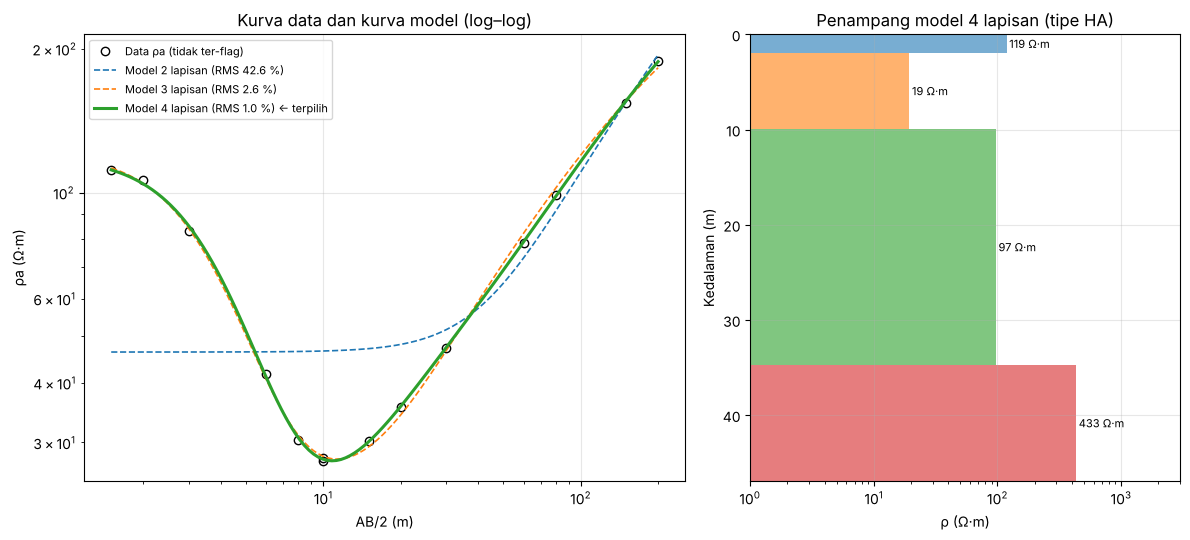

In [6]:
# ---- Prompt 2: model terpilih, tipe kurva, keluaran, gambar ----
M = hasil[n_pilih]
rho_m, h_m = M["rho"], M["h"]
z_bawah = np.r_[np.cumsum(h_m), np.nan]            # kedalaman dasar lapisan (m); lapisan terakhir tak berhingga

def tipe_kurva(r):
    t = ""
    for i in range(1, len(r) - 1):
        if   r[i-1] > r[i] < r[i+1]: t += "H"
        elif r[i-1] < r[i] > r[i+1]: t += "K"
        elif r[i-1] < r[i] < r[i+1]: t += "A"
        elif r[i-1] > r[i] > r[i+1]: t += "Q"
        else: t += "?"
    return t
tk = tipe_kurva(rho_m)

model_ves = pd.DataFrame({
    "Lapisan": np.arange(1, n_pilih + 1),
    "rho (ohm.m)": rho_m.round(1),
    "h (m)": np.r_[h_m, np.nan].round(2),
    "Kedalaman dasar (m)": z_bawah.round(2),
    "RMS error model (%)": round(M["rms"], 2),
})
model_ves.to_csv("model_ves.csv", index=False)
display(model_ves)
print(f"Tipe kurva (urutan lapisan 2 dst. pada triplet): {tk}  <- dasar: perbandingan ρ lapisan i-1, i, i+1")

# ---- Verifikasi (V) ----
cal_ulang = schlum_forward(rho_m, h_m, s_obs)
check("P2", "Forward ulang dari model hasil inversi menghasilkan RMS yang sama dengan yang dilaporkan",
      abs(rms_persen(rho_obs, cal_ulang) - M["rms"]) < 1e-9, f"RMS = {rms_persen(rho_obs, cal_ulang):.3f} %")
ab2_maks = s_obs.max()
z_atas_terdalam = h_m.sum()
check("P2", "Puncak lapisan terdalam wajar terhadap AB/2 maksimum (aturan praktis ≤ 0,5 × AB/2 maks)",
      z_atas_terdalam <= 0.5*ab2_maks, f"puncak lapisan terdalam {z_atas_terdalam:.1f} m; 0,5 × AB/2 maks = {0.5*ab2_maks:.0f} m")
# sensitivitas terhadap model awal
rho_start = np.array([r["rho"] for r in semua_start[n_pilih]])
h_start = np.array([r["h"] for r in semua_start[n_pilih]])
rms_start = np.array([r["rms"] for r in semua_start[n_pilih]])
dekat = rms_start <= 1.2*rms_start.min() + 0.05
print(f"Dari 6 model awal berbeda, {dekat.sum()} menghasilkan RMS ≤ 1,2 × RMS terbaik. Rentang parameter model-model itu:")
rentang = pd.DataFrame({
    "Parameter": [f"ρ{i+1} (Ω·m)" for i in range(n_pilih)] + [f"h{i+1} (m)" for i in range(n_pilih-1)],
    "Minimum": np.r_[rho_start[dekat].min(0), h_start[dekat].min(0)].round(2),
    "Maksimum": np.r_[rho_start[dekat].max(0), h_start[dekat].max(0)].round(2)})
rentang["Maks/Min"] = (rentang["Maksimum"]/rentang["Minimum"]).round(2)
display(rentang)
besar = (rentang["Maks/Min"] > 1.5).any()
print("Kesimpulan sensitivitas: " + ("hasil BERGANTUNG pada model awal (rasio maks/min > 1,5 pada sebagian parameter)." if besar
      else "hasil stabil terhadap model awal (rasio maks/min ≤ 1,5)."))

# ---- Gambar ----
fig, axes = plt.subplots(1, 2, figsize=(12, 5.5), gridspec_kw={"width_ratios": [1.4, 1]})
ax = axes[0]
s_halus = np.geomspace(s_obs.min(), s_obs.max(), 120)
ax.loglog(s_obs, rho_obs, "ko", mfc="none", label="Data ρa (tidak ter-flag)")
for n in (2, 3, 4):
    ax.loglog(s_halus, schlum_forward(hasil[n]["rho"], hasil[n]["h"], s_halus), "-" if n == n_pilih else "--",
              lw=2.2 if n == n_pilih else 1.2, label=f"Model {n} lapisan (RMS {hasil[n]['rms']:.1f} %)" + (" ← terpilih" if n == n_pilih else ""))
ax.set_xlabel("AB/2 (m)"); ax.set_ylabel("ρa (Ω·m)"); ax.set_title("Kurva data dan kurva model (log–log)"); ax.legend(fontsize=8)
ax = axes[1]
zz = np.r_[0, np.cumsum(h_m), np.cumsum(h_m)[-1]*1.35]
for i in range(n_pilih):
    ax.fill_betweenx([zz[i], zz[i+1]], 0, rho_m[i], alpha=0.6, step=None)
    ax.text(rho_m[i]*1.05, (zz[i] + zz[i+1])/2, f"{rho_m[i]:.0f} Ω·m", va="center", fontsize=8)
ax.set_xscale("log"); ax.set_ylim(zz[-1], 0); ax.set_xlim(1, 3000)
ax.set_xlabel("ρ (Ω·m)"); ax.set_ylabel("Kedalaman (m)"); ax.set_title(f"Penampang model {n_pilih} lapisan (tipe {tk})")
plt.tight_layout(); plt.show()

### Interpretasi Prompt 2: hasil hitungan dipisahkan dari dugaan geologi

**Hasil hitungan.** Model 2 lapisan tidak mampu mengikuti kurva (RMS ≈ 43 %). Model 3 lapisan sudah cocok (RMS ≈ 2,6 %), dan model 4 lapisan memberi RMS ≈ 1,0 % dengan BIC terkecil, sehingga dipilih. Model terpilih (tipe kurva **HA**: ρ turun lalu naik bertahap) kira-kira ρ = 119; 19; 97; 433 Ω·m dengan tebal lapisan 2,0; 8,0; 24,8 m. Enam model awal yang berbeda menuju model yang sama, jadi hasil tidak bergantung pada model awal di dalam batas parameter yang dipakai. (Angka dapat berbeda sedikit bila versi paket berbeda.)

**Hal yang harus diwaspadai.** (1) Hanya 14 data dipakai untuk 7 parameter pada model 4 lapisan. (2) RMS model 4 lapisan (≈ 1,0 %) lebih kecil daripada tingkat noise yang diasumsikan (3 %), tanda bahwa sebagian parameter mungkin ikut mencocokkan noise; model 3 lapisan (RMS ≈ 2,6 %) sudah berada di bawah noise dan merupakan alternatif yang sama sahnya. (3) Karena datanya sintetis, model yang membangkitkan data diketahui (ρ = 120; 18; 60; 400 Ω·m, h = 2; 6; 18 m). Lapisan 1–2 pulih dengan baik, sedangkan lapisan 3 dan kedalaman batuan dasar meleset (ρ₃ ≈ 97 vs 60 Ω·m; puncak lapisan ke-4 ≈ 35 m vs 26 m). Pada data lapangan model sebenarnya tidak diketahui, jadi selisih seperti ini tidak dapat dikenali tanpa uji ekuivalensi (Prompt 5) dan data bor (Prompt 4).

**Dugaan geologi (bukan hasil hitungan).** Urutan "tanah penutup lebih resistif → lapisan konduktif → lapisan menengah → lapisan sangat resistif" dapat dikaitkan dengan tanah kering, lempung atau lanau, pasir atau kerikil, dan batuan kompak. Dugaan ini hanya bersandar pada pola resistivitas dan **belum terbukti**; satu nilai ρ dapat berasal dari lebih dari satu material, dan solusi inversi tidak unik.

---

# Catatan Pemakaian Data Asli
Untuk mengganti data sintetis dengan data praktikum: (1) isi berkas data lapangan dengan kolom yang sama (AB/2, MN, I dalam mA, ΔV dalam mV), (2) sesuaikan ambang flag Prompt 1 dengan alat yang dipakai, (3) ganti `SIGMA`, batas ρ dan h, serta jumlah lapisan uji di Prompt 2 sesuai kondisi data.

---

# Prompt 3 — Inversi Dua Dimensi (ERT) dan Pembacaan Penampang Resistivitas

Prompt 3 menyebut perangkat lunak seperti Res2DInv atau pyGIMLi. Agar notebook ini dapat dijalankan **tanpa memasang paket tambahan**, inversi 2D ditulis langsung dengan `numpy`/`scipy` dalam bentuk ringkas. Cara kerjanya sama dengan prinsip program inversi ERT:

1. **Forward 2,5D** (beda hingga, volume hingga): sumber titik pada medium 2D (resistivitas hanya berubah terhadap x dan z) dihitung dalam domain bilangan gelombang searah *strike* (ky), lalu dijumlahkan numerik.
2. **Faktor geometri numerik** dikalibrasi dengan model homogen (mengurangi galat diskretisasi sumber).
3. **Inversi Gauss-Newton** *smoothness-constrained* (regularisasi L2 pada selisih antar-blok ln ρ) dengan Jacobian dari metode adjoint/resiprositas, diverifikasi terhadap beda hingga.

Susunan elektroda: **Wenner–Schlumberger**, 24 elektroda, spasi a = 2 m, level n = 1–6 (96 data). Topografi: **tidak ada**, sehingga **permukaan diasumsikan datar**. Data dibangkitkan dari model sintetis dengan noise 3 %; karena data dan inversi memakai program forward yang sama (*inverse crime*), hasil di sini lebih optimistis daripada data lapangan.

In [7]:
# ---- Prompt 3 (bagian 1): mesh, forward 2.5D, dan Jacobian ----
import scipy.sparse as sp
import scipy.sparse.linalg as spla

# ----- geometri survei -----
n_el, a_el = 24, 2.0
x_el = np.arange(n_el)*a_el                      # posisi elektroda (m)
quad = []                                        # Wenner-Schlumberger: C1 - P1 - P2 - C2
for n in range(1, 7):
    for i in range(n_el - (2*n + 1)):
        quad.append((i, i + n, i + n + 1, i + 2*n + 1, n))
quad = np.array(quad)
ic1, ip1, ip2, ic2, nlev = quad.T
K_geo = np.pi*nlev*(nlev + 1)*a_el                # K WS = π n (n+1) a  (n=1 -> Wenner, 2π a)
x_mid = (x_el[ip1] + x_el[ip2])/2
z_pseudo = a_el*(0.52 + 0.39*(nlev - 1))          # kedalaman semu (perkiraan visual, BUKAN kedalaman sebenarnya)
nd = len(quad)

# ----- mesh volume hingga (sel-sel) -----
npad, fpad = 8, 1.6
pad_w = 1.0*fpad**np.arange(1, npad + 1)
dxs = np.r_[pad_w[::-1], np.ones(47), pad_w]                       # lebar sel (m)
xcs = np.cumsum(dxs) - dxs/2 - dxs[:npad].sum()                    # pusat sel; sel inti berpusat di x = 0,1,...,46
dzs = np.r_[0.5*1.25**np.arange(14), 0.5*1.25**13*1.8**np.arange(1, 5)]
zcs = np.cumsum(dzs) - dzs/2
nx, nz = len(dxs), len(dzs); nc = nx*nz
col_el = npad + (x_el/1.0).astype(int)                             # indeks kolom sel elektroda
cell_el = col_el                                                   # baris z = 0 -> indeks = kolom
IX, IZ = np.meshgrid(np.arange(nx), np.arange(nz))
cid = (IZ*nx + IX)                                                 # indeks sel

# tautan (link) antar-sel
la_h, lb_h = cid[:, :-1].ravel(), cid[:, 1:].ravel()
A_h  = np.repeat(dzs, nx - 1)
da_h, db_h = np.tile(dxs[:-1]/2, nz), np.tile(dxs[1:]/2, nz)
la_v, lb_v = cid[:-1, :].ravel(), cid[1:, :].ravel()
A_v  = np.repeat(dxs[None, :], nz - 1, axis=0).ravel()
da_v, db_v = np.repeat(dzs[:-1]/2, nx), np.repeat(dzs[1:]/2, nx)
la, lb = np.r_[la_h, la_v], np.r_[lb_h, lb_v]
A_l, da_l, db_l = np.r_[A_h, A_v], np.r_[da_h, da_v], np.r_[db_h, db_v]
nl = len(la)
vol = (dzs[:, None]*dxs[None, :]).ravel()                          # luas sel (volume per satuan strike)

# batas Dirichlet (φ = 0) di kiri, kanan, dasar; sisi atas Neumann (udara)
Cb = np.zeros(nc)
Cb[cid[:, 0]]  += dzs/(dxs[0]/2)
Cb[cid[:, -1]] += dzs/(dxs[-1]/2)
Cb[cid[-1, :]] += dxs/(dzs[-1]/2)

# kuadratur bilangan gelombang ky (integral invers Fourier kosinus)
KY = np.geomspace(0.002, 1.0, 12)
u = np.log(KY)
# trapesium pada sumbu ln(ky): ∫ f dky = ∫ f ky d(ln ky); ekor [0, ky_min] didekati f(ky_min)*ky_min
du = np.diff(u); wq = np.zeros(len(KY))
wq[:-1] += 0.5*du*KY[:-1]; wq[1:] += 0.5*du*KY[1:]; wq[0] += KY[0]
wq = wq/np.pi                                                      # faktor 1/π dari transformasi Fourier kosinus

Pa = sp.csr_matrix((np.ones(nl), (la, np.arange(nl))), shape=(nc, nl))
Pb = sp.csr_matrix((np.ones(nl), (lb, np.arange(nl))), shape=(nc, nl))
Dm = (Pa - Pb).T.tocsr()                                           # selisih potensial pada tautan

def _links(sig):
    g = A_l/(da_l/sig[la] + db_l/sig[lb])
    return g

def _solve_all(sig, need_J=False):
    """Mengembalikan G (n_el x n_el, potensial permukaan untuk arus 1 A) dan daftar U (bila need_J)."""
    g = _links(sig)
    G = np.zeros((n_el, n_el)); Us = []
    E = np.zeros((nc, n_el)); E[cell_el, np.arange(n_el)] = 1.0
    for k, ky in enumerate(KY):
        L = sp.coo_matrix((np.r_[g, g, -g, -g], (np.r_[la, lb, la, lb], np.r_[la, lb, lb, la])), shape=(nc, nc)).tocsc()
        A = L + sp.diags(ky**2*sig*vol + sig*Cb)
        U = spla.splu(A).solve(E)
        G += wq[k]*U[cell_el, :]
        if need_J: Us.append(U)
    return G, Us

def _dV(G):
    return G[ip1, ic1] - G[ip1, ic2] - G[ip2, ic1] + G[ip2, ic2]

# kalibrasi faktor geometri numerik dengan setengah ruang homogen 1 Ω·m
G_h, _ = _solve_all(np.ones(nc))
V_h = _dV(G_h)
rho_hom_tanpa_kalibrasi = K_geo*V_h                                # seharusnya = 1 Ω·m
calib = 1.0/rho_hom_tanpa_kalibrasi
print(f"Uji forward homogen (tanpa kalibrasi): ρa/ρ = {rho_hom_tanpa_kalibrasi.min():.3f} – {rho_hom_tanpa_kalibrasi.max():.3f} (ideal 1,000)")

def forward_ert(rho_cell):
    G, _ = _solve_all(1.0/rho_cell)
    return calib*K_geo*_dV(G)

# ----- parameter inversi: blok 2 m lebar x 9 baris kedalaman -----
nbx, nbz = 24, 9
blk_col = np.where(IX < npad, 0, np.where(IX >= npad + 47, nbx - 1, np.minimum((IX - npad)//2, nbx - 1)))
blk_row = np.minimum(IZ, nbz - 1)
blk_of_cell = (blk_row*nbx + blk_col).ravel()
nb = nbx*nbz
Mmap = sp.csr_matrix((np.ones(nc), (np.arange(nc), blk_of_cell)), shape=(nc, nb))   # sel -> blok

def fwd_jac(m):
    """m = ln ρ blok. Mengembalikan ln ρa terhitung dan Jacobian d ln ρa / d ln ρ_blok (nd x nb)."""
    rho_cell = np.exp(Mmap@m); sig = 1.0/rho_cell
    G, Us = _solve_all(sig, need_J=True)
    V = _dV(G)
    g = _links(sig)
    dga = g**2*da_l/(A_l*sig[la]**2); dgb = g**2*db_l/(A_l*sig[lb]**2)
    JV = np.zeros((nd, nb))
    for k, ky in enumerate(KY):
        U = Us[k]
        uAB = U[:, ic1] - U[:, ic2]; uMN = U[:, ip1] - U[:, ip2]
        DU = Dm@U
        S = (DU[:, ic1] - DU[:, ic2])*(DU[:, ip1] - DU[:, ip2])           # nl x nd
        dVds = -(Pa@(dga[:, None]*S) + Pb@(dgb[:, None]*S)) - (ky**2*vol + Cb)[:, None]*uAB*uMN
        JV += wq[k]*(-(Mmap.T@(sig[:, None]*dVds))).T
    return np.log(calib*K_geo*V), JV/V[:, None]

def fwd_ln(m):
    G, _ = _solve_all(1.0/np.exp(Mmap@m))
    return np.log(calib*K_geo*_dV(G))

# ---- verifikasi Jacobian terhadap beda hingga ----
m_uji = np.log(np.full(nb, 80.0)) + 0.4*np.sin(np.arange(nb)/5.0)
_, J_ad = fwd_jac(m_uji)
f0 = fwd_ln(m_uji)
for j in (3, 60, 150):
    mp = m_uji.copy(); mp[j] += 1e-4
    J_fd = (fwd_ln(mp) - f0)/1e-4
    rel = np.linalg.norm(J_ad[:, j] - J_fd)/np.linalg.norm(J_fd)
    check("P3", f"Jacobian adjoint = beda hingga untuk blok {j}", rel < 1e-3, f"selisih relatif = {rel:.1e}")

Uji forward homogen (tanpa kalibrasi): ρa/ρ = 0.850 – 1.007 (ideal 1,000)
[LULUS] Jacobian adjoint = beda hingga untuk blok 3  ->  selisih relatif = 1.9e-05
[LULUS] Jacobian adjoint = beda hingga untuk blok 60  ->  selisih relatif = 1.3e-05
[LULUS] Jacobian adjoint = beda hingga untuk blok 150  ->  selisih relatif = 1.1e-05


### Data ERT sintetis dan kontrol kualitas (QC) sebelum inversi

Model sintetis: latar 80 Ω·m, satu zona konduktif (10 Ω·m, x = 12–24 m, z = 2–6 m) dan satu zona resistif (500 Ω·m, x = 30–42 m, z = 0,8–4,5 m). Noise acak 3 % ditambahkan, ditambah **dua data buruk yang disengaja** untuk menguji QC. Aturan QC: bandingkan ln ρa setiap titik dengan median tetangganya pada level n yang sama (±2 posisi); titik ditandai bila simpangannya > 3,5 × MAD robust **dan** > 0,25 (≈ 28 %). Titik yang dikeluarkan dicatat jumlah, posisi, dan alasannya.

In [8]:
# ---- Prompt 3 (bagian 2): data sintetis + QC ----
rng3 = np.random.default_rng(303)
Xc, Zc = np.meshgrid(xcs, zcs)
rho_true_cell = np.full((nz, nx), 80.0)
rho_true_cell[(Xc >= 12) & (Xc <= 24) & (Zc >= 2.0) & (Zc <= 6.0)] = 10.0
rho_true_cell[(Xc >= 30) & (Xc <= 42) & (Zc >= 0.8) & (Zc <= 4.5)] = 500.0

rho_obs0 = forward_ert(rho_true_cell.ravel())*np.exp(rng3.normal(0, 0.03, nd))
buruk = rng3.choice(nd, 2, replace=False)
rho_obs0[buruk[0]] *= 2.6; rho_obs0[buruk[1]] *= 0.32
print(f"Jumlah data ERT: {nd} (n = 1–6, a = {a_el:g} m, 24 elektroda); rentang ρa: {rho_obs0.min():.1f} – {rho_obs0.max():.1f} Ω·m")

# ---- QC: simpangan terhadap median tetangga pada level n yang sama ----
lnr = np.log(rho_obs0)
dev = np.zeros(nd)
for i in range(nd):
    tetangga = np.where((nlev == nlev[i]) & (np.abs(x_mid - x_mid[i]) <= 2*a_el) & (np.arange(nd) != i))[0]
    dev[i] = lnr[i] - np.median(lnr[tetangga]) if len(tetangga) else 0.0
mad = 1.4826*np.median(np.abs(dev - np.median(dev)))
flag_qc = (np.abs(dev) > 3.5*mad) & (np.abs(dev) > 0.25)
print(f"MAD robust simpangan = {mad:.3f}; jumlah data ditandai = {flag_qc.sum()}")
tab_qc = pd.DataFrame({"No": np.where(flag_qc)[0] + 1, "x tengah (m)": x_mid[flag_qc], "level n": nlev[flag_qc],
                       "ρa (Ω·m)": rho_obs0[flag_qc].round(1), "simpangan ln ρa": dev[flag_qc].round(2),
                       "alasan": "simpangan > 3,5×MAD dan > 0,25 dari median tetangga level n sama"})
display(tab_qc)
print("Data yang SEBENARNYA dibuat buruk (hanya diketahui karena data sintetis): No", sorted((buruk + 1).tolist()))
print("Tidak semua data ter-flag otomatis berarti salah: pada data nyata periksa catatan lapangan lebih dulu.")

keep = ~flag_qc
rho_ert = rho_obs0[keep]
print(f"Data yang dipakai inversi: {keep.sum()} dari {nd}; data dikeluarkan: {(~keep).sum()}")

Jumlah data ERT: 96 (n = 1–6, a = 2 m, 24 elektroda); rentang ρa: 19.5 – 241.5 Ω·m
MAD robust simpangan = 0.162; jumlah data ditandai = 2


,No,x tengah (m),level n,ρa (Ω·m),simpangan ln ρa,alasan
0,4,9.0,1,191.9,0.98,"simpangan > 3,5×MAD dan > 0,25 dari median tet..."
1,91,23.0,6,19.5,-1.03,"simpangan > 3,5×MAD dan > 0,25 dari median tet..."


Data yang SEBENARNYA dibuat buruk (hanya diketahui karena data sintetis): No [4, 91]
Tidak semua data ter-flag otomatis berarti salah: pada data nyata periksa catatan lapangan lebih dulu.
Data yang dipakai inversi: 94 dari 96; data dikeluarkan: 2


### Inversi: parameter dan hasil

Parameter inversi (dinyatakan eksplisit sesuai batasan Prompt 3):

- Regularisasi: *smoothness-constrained* L2, minimalkan $\|d-f(m)\|^2+\lambda\|Rm\|^2$ dengan $R$ operator selisih horizontal dan vertikal antar-blok, $m=\ln\rho$.
- Faktor redaman λ: dipilih dari tiga nilai (0,003; 0,03; 0,3) berdasarkan **prinsip diskrepansi** (RMS akhir mendekati tingkat noise 3 %), bukan RMS terkecil.
- Model awal: homogen, ρ = rata-rata geometrik ρa terukur.
- Kriteria berhenti: maksimum 10 iterasi, atau RMS sudah ≤ 3 % (tingkat noise) **dan** perubahan RMS antar-iterasi < 3 % relatif.
- Pencarian langkah: *backtracking* (faktor 1; 0,5; 0,25; 0,125) pada fungsi tujuan total.

In [9]:
# ---- Prompt 3 (bagian 3): inversi Gauss-Newton smoothness-constrained ----
# operator kehalusan antar-blok
rows_R, cols_R, vals_R = [], [], []
r = 0
for iz in range(nbz):
    for ix in range(nbx):
        b = iz*nbx + ix
        if ix + 1 < nbx:
            rows_R += [r, r]; cols_R += [b, b + 1]; vals_R += [-1, 1]; r += 1
        if iz + 1 < nbz:
            rows_R += [r, r]; cols_R += [b, b + nbx]; vals_R += [-1, 1]; r += 1
R = sp.csr_matrix((vals_R, (rows_R, cols_R)), shape=(r, nb))
RtR = (R.T@R).toarray()

# data untuk inversi: hanya yang lolos QC -> potong Jacobian pada baris keep
def invert(lam, n_iter=10, target_rms=3.0, verbose=False):
    d = np.log(rho_ert)
    m = np.full(nb, np.mean(np.log(rho_ert)))
    riwayat = []
    for it in range(n_iter + 1):
        f, J = fwd_jac(m)
        f, J = f[keep], J[keep]
        res = d - f
        rms = 100*np.sqrt(np.mean((np.expm1(-res))**2))            # galat relatif ρa (%)
        riwayat.append(rms)
        if it == n_iter: break
        if len(riwayat) >= 2 and riwayat[-1] <= target_rms and abs(riwayat[-2] - riwayat[-1])/riwayat[-2] < 0.03:
            break
        H = J.T@J + lam*RtR
        dm = np.linalg.solve(H, J.T@res - lam*(RtR@m))
        phi0 = res@res + lam*m@RtR@m
        for alpha in (1.0, 0.5, 0.25, 0.125):
            mt = m + alpha*dm
            rt = d - fwd_ln(mt)[keep]
            if rt@rt + lam*mt@RtR@mt < phi0: m = mt; break
        else:
            break
    f, J = fwd_jac(m)
    return m, riwayat, J[keep]

hasil_lam = {}
for lam in (0.003, 0.03, 0.3):
    m_l, riw, J_l = invert(lam)
    hasil_lam[lam] = (m_l, riw, J_l)
    print(f"λ = {lam:<6g}: {len(riw)-1} iterasi, RMS akhir = {riw[-1]:.2f} %")

lam_pilih = min(hasil_lam, key=lambda l: abs(hasil_lam[l][1][-1] - 3.0))
m_fin, riw_fin, J_fin = hasil_lam[lam_pilih]
print(f"\nλ terpilih (RMS akhir paling dekat dengan noise 3 %): {lam_pilih:g}")
tab_iter = pd.DataFrame({"Iterasi": np.arange(len(riw_fin)), "RMS error (%)": np.round(riw_fin, 2)})
display(tab_iter)
print(f"RMS akhir = {riw_fin[-1]:.2f} %  (tingkat noise yang dibangkitkan = 3 %)")

λ = 0.003 : 4 iterasi, RMS akhir = 2.91 %
λ = 0.03  : 10 iterasi, RMS akhir = 5.23 %
λ = 0.3   : 10 iterasi, RMS akhir = 14.54 %

λ terpilih (RMS akhir paling dekat dengan noise 3 %): 0.003


,Iterasi,RMS error (%)
0,0,71.58
1,1,20.95
2,2,7.68
3,3,2.96
4,4,2.91


RMS akhir = 2.91 %  (tingkat noise yang dibangkitkan = 3 %)


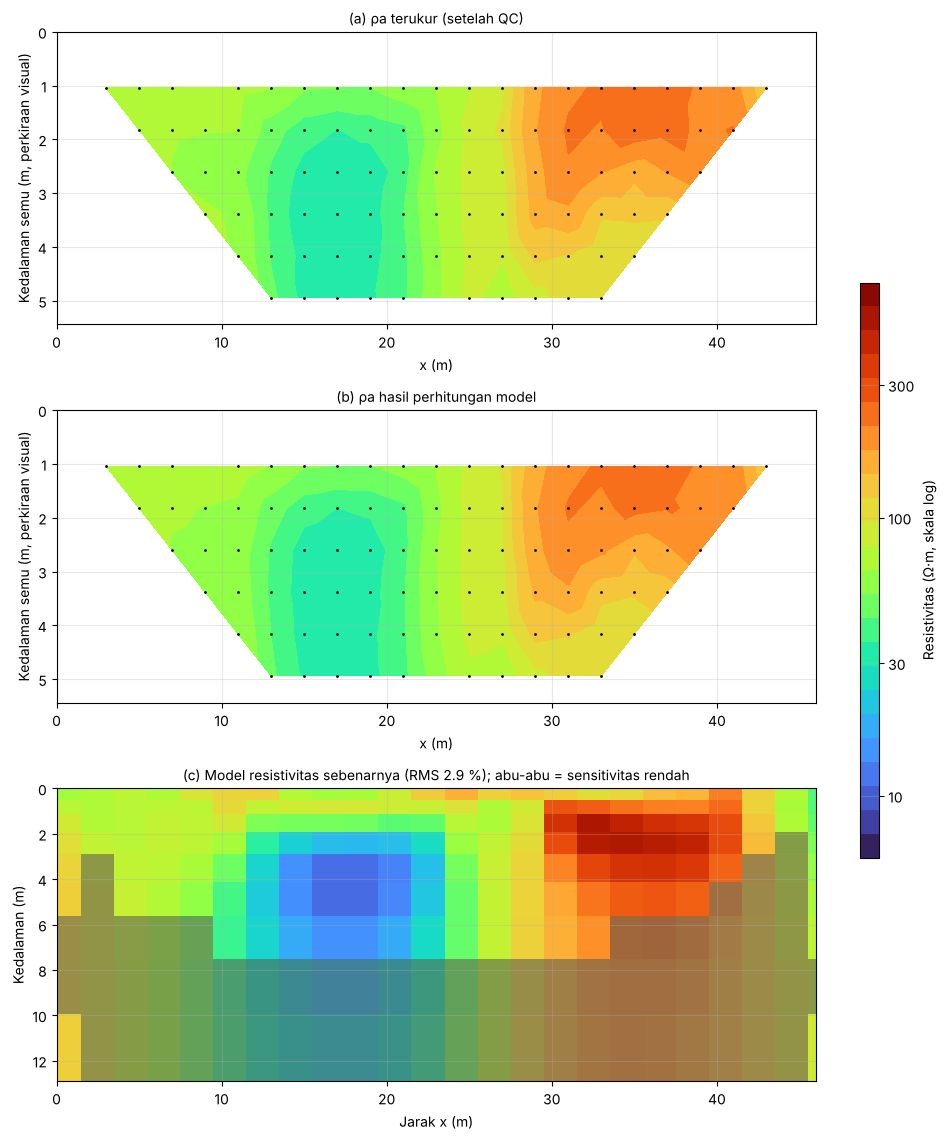

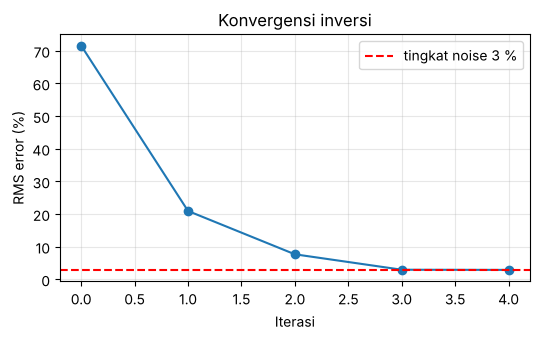

In [10]:
# ---- Prompt 3 (bagian 4): perbandingan tiga penampang dan penampang model ----
rho_cal = np.exp(fwd_ln(m_fin))
from matplotlib.colors import LogNorm
from matplotlib.tri import Triangulation

def pseudo(ax, rho, tampil, judul, vmin, vmax):
    tri = Triangulation(x_mid[tampil], z_pseudo[tampil])
    cf = ax.tricontourf(tri, rho[tampil], levels=np.geomspace(vmin, vmax, 25), norm=LogNorm(vmin, vmax), cmap="turbo")
    ax.plot(x_mid[tampil], z_pseudo[tampil], "k.", ms=2)
    ax.set_ylim(z_pseudo.max() + 0.5, 0); ax.set_xlim(0, 46)
    ax.set_title(judul, fontsize=10); ax.set_xlabel("x (m)")
    return cf
vmin, vmax = 6.0, 700.0
fig, axes = plt.subplots(3, 1, figsize=(9.5, 11.5))
cf = pseudo(axes[0], rho_obs0, keep, "(a) ρa terukur (setelah QC)", vmin, vmax)
pseudo(axes[1], rho_cal, keep, "(b) ρa hasil perhitungan model", vmin, vmax)
for a in axes[:2]: a.set_ylabel("Kedalaman semu (m, perkiraan visual)")
ax = axes[2]
cov = np.abs(J_fin).sum(0).reshape(nbz, nbx)
cov = cov/np.percentile(cov, 95)
zedge = np.r_[0, np.cumsum(dzs)][:nbz + 1]
xedge = np.r_[-0.5, np.arange(1.5, 46, 2.0), 46.5]            # batas blok (24 kolom, tiap blok 2 sel lebar 1 m)
mod_blok = np.exp(m_fin).reshape(nbz, nbx)
pm = ax.pcolormesh(xedge, zedge, mod_blok, norm=LogNorm(vmin, vmax), cmap="turbo", shading="flat")
ax.pcolormesh(xedge, zedge, np.where(cov < 0.12, 1.0, np.nan), cmap="gray_r", vmin=0, vmax=1.5, alpha=0.55, shading="flat")
ax.set_ylim(zedge[-1], 0); ax.set_xlim(0, 46)
ax.set_xlabel("Jarak x (m)"); ax.set_ylabel("Kedalaman (m)")
ax.set_title(f"(c) Model resistivitas sebenarnya (RMS {riw_fin[-1]:.1f} %); abu-abu = sensitivitas rendah", fontsize=10)
plt.tight_layout(rect=(0, 0, 0.88, 1))
cax = fig.add_axes([0.91, 0.25, 0.02, 0.5])
cb = fig.colorbar(cf, cax=cax, label="Resistivitas (Ω·m, skala log)")
cb.set_ticks([10, 30, 100, 300]); cb.set_ticklabels(["10", "30", "100", "300"]); cb.ax.minorticks_off()
plt.show()

fig, ax = plt.subplots(figsize=(5.5, 3.5))
ax.plot(np.arange(len(riw_fin)), riw_fin, "o-"); ax.axhline(3.0, color="r", ls="--", label="tingkat noise 3 %")
ax.set_xlabel("Iterasi"); ax.set_ylabel("RMS error (%)"); ax.set_title("Konvergensi inversi"); ax.legend()
plt.tight_layout(); plt.show()

In [11]:
# ---- Prompt 3 (bagian 5): Verifikasi (V) ----
# (1) data terukur vs model hitung
sisa = (np.log(rho_obs0[keep]) - np.log(rho_cal[keep]))
r_pearson = np.corrcoef(np.log(rho_obs0[keep]), np.log(rho_cal[keep]))[0, 1]
check("P3", "Pola ρa terukur dan ρa model mirip (korelasi ln ρa > 0,95)", r_pearson > 0.95, f"r = {r_pearson:.3f}")
print(f"Residual ln ρa: rata-rata = {sisa.mean():+.3f}; simpangan baku = {sisa.std():.3f}; |maks| = {np.abs(sisa).max():.3f} (selisih besar perlu dijelaskan)")
# (2) konvergensi: perubahan RMS antar-iterasi melandai
if len(riw_fin) >= 3:
    perubahan = abs(riw_fin[-2] - riw_fin[-1])/riw_fin[-2]
    check("P3", "RMS antar-iterasi melandai (perubahan iterasi terakhir < 10 %)", perubahan < 0.10, f"perubahan = {100*perubahan:.1f} %")
# (3) kestabilan terhadap faktor redaman
m_ref = m_fin
cover_mask = (np.abs(J_fin).sum(0) > 0.12*np.percentile(np.abs(J_fin).sum(0), 95))
print("\nKestabilan struktur terhadap faktor redaman (korelasi ln ρ model pada blok ber-sensitivitas memadai):")
for lam, (m_l, riw, _) in hasil_lam.items():
    c = np.corrcoef(m_ref[cover_mask], m_l[cover_mask])[0, 1]
    print(f"  λ = {lam:<6g}: RMS = {riw[-1]:5.2f} %, korelasi dengan model terpilih = {c:.3f}")
c_min = min(np.corrcoef(m_ref[cover_mask], m_l[cover_mask])[0, 1] for m_l, _, _ in hasil_lam.values())
check("P3", "Struktur utama stabil terhadap perubahan redaman (korelasi minimum > 0,8)", c_min > 0.8, f"korelasi minimum = {c_min:.3f}")
# (4) zona anomali: lokasi pusat hasil inversi
mod2 = np.exp(m_fin).reshape(nbz, nbx)
xb = 0.5*(xedge[:-1] + xedge[1:]); zb = 0.5*(zedge[:-1] + zedge[1:])
iz_lo, ix_lo = np.unravel_index(np.argmin(np.where(cov > 0.12, mod2, np.inf)), mod2.shape)
iz_hi, ix_hi = np.unravel_index(np.argmax(np.where(cov > 0.12, mod2, -np.inf)), mod2.shape)
print(f"\nResistivitas terendah di model: {mod2[iz_lo, ix_lo]:.1f} Ω·m pada x ≈ {xb[ix_lo]:.0f} m, z ≈ {zb[iz_lo]:.1f} m  (zona konduktif sintetis: x 12–24 m, z 2–6 m)")
print(f"Resistivitas tertinggi di model: {mod2[iz_hi, ix_hi]:.1f} Ω·m pada x ≈ {xb[ix_hi]:.0f} m, z ≈ {zb[iz_hi]:.1f} m  (zona resistif sintetis: x 30–42 m, z 0,8–4,5 m)")
print("Catatan: pada data lapangan, regularisasi dan resolusi yang menurun terhadap kedalaman membuat batas anomali tampak lebih halus dan amplitudonya bisa meleset;\n         di sini hasil lebih dekat ke model sintetis karena data dan inversi memakai forward yang sama (inverse crime).")

[LULUS] Pola ρa terukur dan ρa model mirip (korelasi ln ρa > 0,95)  ->  r = 0.999
Residual ln ρa: rata-rata = +0.000; simpangan baku = 0.029; |maks| = 0.081 (selisih besar perlu dijelaskan)
[LULUS] RMS antar-iterasi melandai (perubahan iterasi terakhir < 10 %)  ->  perubahan = 1.8 %

Kestabilan struktur terhadap faktor redaman (korelasi ln ρ model pada blok ber-sensitivitas memadai):
  λ = 0.003 : RMS =  2.91 %, korelasi dengan model terpilih = 1.000
  λ = 0.03  : RMS =  5.23 %, korelasi dengan model terpilih = 0.985
  λ = 0.3   : RMS = 14.54 %, korelasi dengan model terpilih = 0.875
[LULUS] Struktur utama stabil terhadap perubahan redaman (korelasi minimum > 0,8)  ->  korelasi minimum = 0.875

Resistivitas terendah di model: 11.0 Ω·m pada x ≈ 18 m, z ≈ 4.9 m  (zona konduktif sintetis: x 12–24 m, z 2–6 m)
Resistivitas tertinggi di model: 519.0 Ω·m pada x ≈ 32 m, z ≈ 1.5 m  (zona resistif sintetis: x 30–42 m, z 0,8–4,5 m)
Catatan: pada data lapangan, regularisasi dan resolusi yang menur

### Interpretasi Prompt 3: pola resistivitas dan dugaan geologi

**Deskripsi pola (hasil inversi).** Pada penampang model terlihat (i) latar belakang bernilai menengah sekitar 80–120 Ω·m; (ii) **zona resistivitas rendah** (minimum ≈ 11 Ω·m) di sekitar x ≈ 12–24 m pada kedalaman kira-kira 2–8 m, yang melebar dan memudar ke bawah; (iii) **zona resistivitas tinggi** (maksimum ≈ 500 Ω·m) di sekitar x ≈ 30–40 m pada kedalaman dangkal sekitar 1–6 m. Batas kedua zona tampak gradual, bukan tegas, karena regularisasi kehalusan. Bagian abu-abu (tepi kiri-kanan dan bagian dalam, terutama di bawah ±6–8 m) memiliki sensitivitas data rendah, sehingga nilai di sana **tidak boleh ditafsirkan sama andalnya** dengan bagian tengah-atas.

**Kualitas inversi.** RMS akhir ≈ 2,9 % setelah 4 iterasi, sebanding dengan tingkat noise yang dibangkitkan (3 %), jadi model tidak kurang cocok dan tidak terlalu dipaksakan; RMS antar-iterasi sudah melandai. Struktur utama bertahan ketika λ dinaikkan 10× dan 100× (korelasi ln ρ model ≥ 0,87), walaupun RMS ikut naik. Karena data dan inversi memakai program forward yang sama (*inverse crime*) serta tidak ada topografi, hasil ini lebih optimistis daripada data lapangan.

**Dugaan geologi (bukan hasil hitungan).** Zona rendah dapat berhubungan dengan material berlempung, tanah jenuh air, atau air bersalinitas tinggi; zona tinggi dapat berhubungan dengan material kering, kompak, atau rongga. Warna atau nilai resistivitas saja **tidak cukup** untuk menentukan litologi; dugaan harus diuji dengan data bor, singkapan, atau metode lain.

**Keterbatasan.** Program inversi di sini ringkas (forward 2,5D beda hingga dan blok parameter 2 m × 9 baris) dan dibuat untuk memperlihatkan alur kerja. Untuk data lapangan dan laporan resmi gunakan perangkat lunak yang tervalidasi (Res2DInv, pyGIMLi, dll.) dan masukkan topografi bila ada.

---

# Prompt 4 — Interpretasi Litologi dan Zona Air Tanah dengan Data Bor

Kode berikut memakai **model VES dari Prompt 2** (`model_ves.csv`) dan **data bor sintetis** yang dibuat sebagai pengganti data bor sumur terdekat (jarak dari lintasan 25 m, muka air tanah 8,5 m dari permukaan tanah). Nilai resistivitas hasil pemodelan **tidak diubah**.

Kelas resistivitas di bawah ini adalah **kelas ilustratif buatan untuk latihan**, sengaja dibuat saling tumpang tindih dalam pilihan materialnya. Pada tugas sebenarnya, ganti dengan tabel rentang resistivitas dari sumber acuan yang Anda sitir (isi: `SUMBER_ACUAN`). Hubungan Archie **tidak dipakai** karena porositas, ρ air pori, dan parameter Archie tidak tersedia dari data (tidak boleh ditebak).

In [12]:
# ---- Prompt 4 (bagian 1): model resistivitas, data bor, kelas resistivitas ----
SUMBER_ACUAN = "[ISI: sumber tabel rentang resistivitas yang Anda pakai]  (kelas di bawah = ilustratif untuk latihan)"
JARAK_BOR_M = 25.0          # jarak titik bor dari lintasan VES (m)
MUKA_AIR_M = 8.5            # kedalaman muka air tanah dari data bor (m, dari permukaan tanah)
Z_TAMPIL = 40.0             # batas tampilan kedalaman (m); lapisan terakhir sebenarnya tak berhingga

mod = pd.read_csv("model_ves.csv")                       # hasil Prompt 2 (tidak diubah)
rho_l = mod["rho (ohm.m)"].values
z_bawah_l = mod["Kedalaman dasar (m)"].values.copy()
z_atas_l = np.r_[0.0, z_bawah_l[:-1]]
z_bawah_l[-1] = Z_TAMPIL

bor = pd.DataFrame({
    "Atas (m)":  [0.0, 2.5, 9.0, 25.0],
    "Bawah (m)": [2.5, 9.0, 25.0, 40.0],
    "Litologi bor": ["pasir lempungan kering (tanah penutup)", "lempung", "pasir-kerikil jenuh air", "batuan dasar lapuk, kompak"],
    "Kelompok": ["tanah", "lempung", "pasir_jenuh", "batuan"]})
bor.to_csv("bor_sintetis.csv", index=False)
bor = pd.read_csv("bor_sintetis.csv")
display(bor)

kelas = [(0, 15, "Sangat rendah", "lempung jenuh air atau air bersalinitas tinggi"),
         (15, 50, "Rendah-sedang", "lempung, lempung pasiran, atau pasir lempungan jenuh air"),
         (50, 150, "Sedang", "pasir/kerikil (jenuh bila di bawah muka air) atau tanah pasiran kering"),
         (150, 1e9, "Tinggi", "material kering, batuan kompak, atau batuan dasar")]
def kelas_dari(r):
    for lo, hi, nama, mat in kelas:
        if lo <= r < hi: return nama
# kelas resistivitas yang masih masuk akal untuk tiap kelompok litologi bor (asumsi pembelajaran)
cocok = {"tanah": ["Sedang", "Tinggi"], "lempung": ["Sangat rendah", "Rendah-sedang"],
         "pasir_jenuh": ["Rendah-sedang", "Sedang"], "batuan": ["Tinggi"]}
print(f"Sumber tabel acuan : {SUMBER_ACUAN}")
print(f"Jarak bor dari lintasan: {JARAK_BOR_M:g} m; muka air tanah: {MUKA_AIR_M:g} m. Kedalaman model dan bor sama-sama diukur dari permukaan tanah (datum sama, satuan meter).")

tab_kelas = pd.DataFrame({
    "Lapisan": mod["Lapisan"], "ρ (Ω·m)": rho_l, "Kelas resistivitas": [kelas_dari(r) for r in rho_l],
    "Dugaan material (bukan kepastian)": [[k[3] for k in kelas if k[2] == kelas_dari(r)][0] for r in rho_l]})

,Atas (m),Bawah (m),Litologi bor,Kelompok
0,0.0,2.5,pasir lempungan kering (tanah penutup),tanah
1,2.5,9.0,lempung,lempung
2,9.0,25.0,pasir-kerikil jenuh air,pasir_jenuh
3,25.0,40.0,"batuan dasar lapuk, kompak",batuan


Sumber tabel acuan : [ISI: sumber tabel rentang resistivitas yang Anda pakai]  (kelas di bawah = ilustratif untuk latihan)
Jarak bor dari lintasan: 25 m; muka air tanah: 8.5 m. Kedalaman model dan bor sama-sama diukur dari permukaan tanah (datum sama, satuan meter).


In [13]:
# ---- Prompt 4 (bagian 2): tabel korelasi kedalaman dengan data bor ----
def overlap(a1, a2, b1, b2): return max(0.0, min(a2, b2) - max(a1, b1))
baris, ket_list = [], []
for i in range(len(rho_l)):
    zt, zb = z_atas_l[i], z_bawah_l[i]
    ov = [(overlap(zt, zb, r["Atas (m)"], r["Bawah (m)"]), r["Kelompok"], r["Litologi bor"]) for _, r in bor.iterrows()]
    ov.sort(reverse=True)
    dom_len, dom_kel, dom_lit = ov[0]
    frac = dom_len/(zb - zt)
    kls = kelas_dari(rho_l[i])
    ok_kelas = kls in cocok[dom_kel]
    if ok_kelas and frac >= 0.7:   verdict = "sesuai"
    elif ok_kelas or any(l/(zb - zt) >= 0.3 and kls in cocok[k] for l, k, _ in ov): verdict = "sebagian"
    else:                          verdict = "tidak sesuai"
    # selisih batas atas terhadap batas litologi bor terdekat
    batas_bor = np.r_[bor["Atas (m)"].values, bor["Bawah (m)"].values]
    d_batas = np.min(np.abs(batas_bor - zt)) if zt > 0 else 0.0
    if verdict == "sesuai" and d_batas > 3.0: verdict = "sebagian"      # litologi cocok tetapi batas bergeser > 3 m
    alasan = (f"litologi dominan bor = '{dom_lit}' ({100*frac:.0f}% dari tebal lapisan); kelas '{kls}' "
              + ("termasuk" if ok_kelas else "TIDAK termasuk") + " kelas yang diharapkan untuk litologi itu")
    if zt > 0: alasan += f"; batas atas berbeda {d_batas:.1f} m dari batas bor terdekat" + (" (> 3 m, kecocokan diturunkan)" if d_batas > 3.0 else "")
    baris.append({"Lapisan": i + 1, "Kedalaman (m)": f"{zt:.1f} – {('~' if i == len(rho_l)-1 else '') + format(zb, '.1f')}",
                  "ρ (Ω·m)": rho_l[i], "Kelas": kls, "Litologi bor dominan": dom_lit,
                  "Kecocokan": verdict, "Alasan": alasan})
korelasi = pd.DataFrame(baris)
pd.set_option("display.max_colwidth", 200)
print("Tabel korelasi kedalaman (model geolistrik vs data bor):")
display(korelasi)

print("\nTabel kelas resistivitas, dugaan material, dan tingkat keyakinan:")
yakin = {"sesuai": "tinggi", "sebagian": "sedang", "tidak sesuai": "rendah"}
tab_kelas["Keyakinan"] = [yakin[v] for v in korelasi["Kecocokan"]]
display(tab_kelas)

Tabel korelasi kedalaman (model geolistrik vs data bor):


,Lapisan,Kedalaman (m),ρ (Ω·m),Kelas,Litologi bor dominan,Kecocokan,Alasan
0,1,0.0 – 2.0,118.6,Sedang,pasir lempungan kering (tanah penutup),sesuai,litologi dominan bor = 'pasir lempungan kering (tanah penutup)' (100% dari tebal lapisan); kelas 'Sedang' termasuk kelas yang diharapkan untuk litologi itu
1,2,2.0 – 9.9,19.4,Rendah-sedang,lempung,sesuai,litologi dominan bor = 'lempung' (82% dari tebal lapisan); kelas 'Rendah-sedang' termasuk kelas yang diharapkan untuk litologi itu; batas atas berbeda 0.5 m dari batas bor terdekat
2,3,9.9 – 34.8,97.1,Sedang,pasir-kerikil jenuh air,sebagian,litologi dominan bor = 'pasir-kerikil jenuh air' (61% dari tebal lapisan); kelas 'Sedang' termasuk kelas yang diharapkan untuk litologi itu; batas atas berbeda 0.9 m dari batas bor terdekat
3,4,34.8 – ~40.0,433.3,Tinggi,"batuan dasar lapuk, kompak",sebagian,"litologi dominan bor = 'batuan dasar lapuk, kompak' (100% dari tebal lapisan); kelas 'Tinggi' termasuk kelas yang diharapkan untuk litologi itu; batas atas berbeda 5.2 m dari batas bor terdekat (>..."



Tabel kelas resistivitas, dugaan material, dan tingkat keyakinan:


,Lapisan,ρ (Ω·m),Kelas resistivitas,Dugaan material (bukan kepastian),Keyakinan
0,1,118.6,Sedang,pasir/kerikil (jenuh bila di bawah muka air) atau tanah pasiran kering,tinggi
1,2,19.4,Rendah-sedang,"lempung, lempung pasiran, atau pasir lempungan jenuh air",tinggi
2,3,97.1,Sedang,pasir/kerikil (jenuh bila di bawah muka air) atau tanah pasiran kering,sedang
3,4,433.3,Tinggi,"material kering, batuan kompak, atau batuan dasar",sedang


In [14]:
# ---- Prompt 4 (bagian 3): muka air tanah, kandidat akuifer, dan verifikasi ----
# (V1) datum dan satuan sama
check("P4", "Semua batas lapisan geolistrik berada dalam rentang kedalaman bor (datum dan satuan sama)",
      z_atas_l.max() <= bor["Bawah (m)"].max() and (z_atas_l >= 0).all(), f"batas terdalam {z_atas_l.max():.1f} m; bor sampai {bor['Bawah (m)'].max():.0f} m")

# (V2) muka air tanah vs penurunan resistivitas pada model
i_wt = int(np.where((z_atas_l <= MUKA_AIR_M) & (MUKA_AIR_M < z_bawah_l))[0][0])
batas_model = z_atas_l[1:]
dekat_wt = batas_model[np.argmin(np.abs(batas_model - MUKA_AIR_M))]
i_dekat = int(np.where(z_atas_l == dekat_wt)[0][0])
turun = rho_l[i_dekat] < rho_l[i_dekat - 1]
konsisten = (abs(dekat_wt - MUKA_AIR_M) <= 3.0) and turun
print(f"Muka air tanah {MUKA_AIR_M:g} m berada di lapisan {i_wt+1} ({z_atas_l[i_wt]:.1f}–{z_bawah_l[i_wt]:.1f} m). "
      f"Batas model terdekat: {dekat_wt:.1f} m (selisih {abs(dekat_wt-MUKA_AIR_M):.1f} m); ρ berubah {rho_l[i_dekat-1]:.0f} → {rho_l[i_dekat]:.0f} Ω·m "
      f"({'turun' if turun else 'NAIK'}).")
check("P4", "Muka air tanah konsisten dengan penurunan resistivitas pada batas model terdekat (≤ 3 m)", konsisten)
if not konsisten:
    print("  -> Penjelasan yang mungkin: (a) muka air berada di bawah/dalam lapisan lempung yang sudah konduktif sehingga kontras air tidak muncul; "
          "(b) lapisan lempung bersifat menekan (semi-confined) atau terisi air kapiler; (c) batas VES tidak unik (ekuivalensi, Prompt 5) dan bor berjarak "
          f"{JARAK_BOR_M:g} m dari lintasan. Keyakinan lapisan yang berhubungan dengan muka air diturunkan satu tingkat.")

# (V3) kandidat akuifer: lapisan bertingkat resistivitas rendah–sedang, di bawah muka air, dan bor menyebut pasir/kerikil jenuh
turunkan = {"tinggi": "sedang", "sedang": "rendah", "rendah": "rendah"}
kandidat = []
for i in range(len(rho_l)):
    kls = kelas_dari(rho_l[i])
    dom_lit = korelasi.loc[i, "Litologi bor dominan"]
    di_bawah_wt = z_bawah_l[i] > MUKA_AIR_M
    if kls in ("Rendah-sedang", "Sedang") and di_bawah_wt and "pasir" in dom_lit and "jenuh" in dom_lit:
        kand = yakin[korelasi.loc[i, "Kecocokan"]]
        bukti = []
        # bukti penyangkal 1: resistivitas rendah dapat berasal dari lempung/air asin
        ref1 = ("pasir" in dom_lit)
        bukti.append(("ρ rendah–sedang juga cocok untuk lempung pasiran / air asin", "terbantahkan sebagian (bor menyebut pasir-kerikil jenuh, bukan lempung)" if ref1 else "TIDAK terbantahkan"))
        # bukti penyangkal 2: bor berjarak dari lintasan; lapisan bisa menipis
        bukti.append((f"bor berjarak {JARAK_BOR_M:g} m dari lintasan; kemenerusan lateral tidak teruji", "TIDAK terbantahkan oleh data yang ada"))
        # bukti penyangkal 3: ketidakcocokan batas bawah/atas
        zt = z_atas_l[i]; selisih = np.min(np.abs(np.r_[bor['Atas (m)'].values, bor['Bawah (m)'].values] - zt))
        bukti.append((f"batas atas model ({zt:.1f} m) berbeda {selisih:.1f} m dari batas bor", "terbantahkan" if selisih <= 1.5 else "TIDAK terbantahkan sepenuhnya"))
        if not konsisten: kand = turunkan[kand]
        if any("TIDAK" in b[1] for b in bukti[2:]) and kand == "tinggi": kand = "sedang"
        kandidat.append({"Lapisan": i + 1, "Kedalaman (m)": f"{zt:.1f} – {z_bawah_l[i]:.1f}", "ρ (Ω·m)": rho_l[i],
                         "Keyakinan potensi akuifer": kand,
                         "Bukti penyangkal": " | ".join(f"{b[0]} → {b[1]}" for b in bukti)})
kandidat = pd.DataFrame(kandidat)
print("\nLapisan yang berpotensi menjadi akuifer (BUKAN penentuan produktivitas; tanpa perkiraan debit atau kualitas air):")
display(kandidat if len(kandidat) else pd.DataFrame({"Hasil": ["tidak ada lapisan yang memenuhi kriteria"]}))

[LULUS] Semua batas lapisan geolistrik berada dalam rentang kedalaman bor (datum dan satuan sama)  ->  batas terdalam 34.8 m; bor sampai 40 m
Muka air tanah 8.5 m berada di lapisan 2 (2.0–9.9 m). Batas model terdekat: 9.9 m (selisih 1.4 m); ρ berubah 19 → 97 Ω·m (NAIK).
[GAGAL] Muka air tanah konsisten dengan penurunan resistivitas pada batas model terdekat (≤ 3 m)
  -> Penjelasan yang mungkin: (a) muka air berada di bawah/dalam lapisan lempung yang sudah konduktif sehingga kontras air tidak muncul; (b) lapisan lempung bersifat menekan (semi-confined) atau terisi air kapiler; (c) batas VES tidak unik (ekuivalensi, Prompt 5) dan bor berjarak 25 m dari lintasan. Keyakinan lapisan yang berhubungan dengan muka air diturunkan satu tingkat.

Lapisan yang berpotensi menjadi akuifer (BUKAN penentuan produktivitas; tanpa perkiraan debit atau kualitas air):


,Lapisan,Kedalaman (m),ρ (Ω·m),Keyakinan potensi akuifer,Bukti penyangkal
0,3,9.9 – 34.8,97.1,rendah,"ρ rendah–sedang juga cocok untuk lempung pasiran / air asin → terbantahkan sebagian (bor menyebut pasir-kerikil jenuh, bukan lempung) | bor berjarak 25 m dari lintasan; kemenerusan lateral tidak t..."


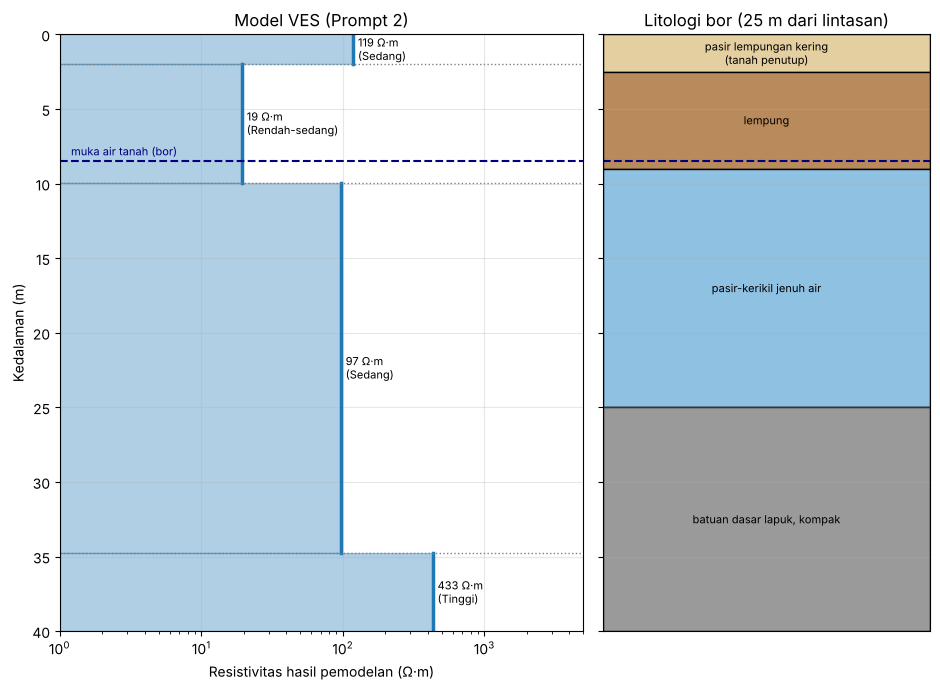

In [15]:
# ---- Prompt 4 (bagian 4): gambar model resistivitas berdampingan dengan kolom litologi bor ----
warna = {"tanah": "#e3cf9f", "lempung": "#b98a5b", "pasir_jenuh": "#8fc1e3", "batuan": "#9a9a9a"}
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(9.5, 7), sharey=True, gridspec_kw={"width_ratios": [1.6, 1]})
for i in range(len(rho_l)):
    ax1.fill_betweenx([z_atas_l[i], z_bawah_l[i]], 1, rho_l[i], color="tab:blue", alpha=0.35)
    ax1.plot([rho_l[i]]*2, [z_atas_l[i], z_bawah_l[i]], color="tab:blue", lw=2.5)
    ax1.text(rho_l[i]*1.08, (z_atas_l[i] + z_bawah_l[i])/2, f"{rho_l[i]:.0f} Ω·m\n({kelas_dari(rho_l[i])})", va="center", fontsize=8)
for zb in z_atas_l[1:]: ax1.axhline(zb, color="gray", ls=":", lw=1)
ax1.axhline(MUKA_AIR_M, color="navy", ls="--", lw=1.5); ax1.text(1.2, MUKA_AIR_M - 0.4, "muka air tanah (bor)", color="navy", fontsize=8)
ax1.set_xscale("log"); ax1.set_xlim(1, 5000); ax1.set_ylim(Z_TAMPIL, 0)
ax1.set_xlabel("Resistivitas hasil pemodelan (Ω·m)"); ax1.set_ylabel("Kedalaman (m)")
ax1.set_title("Model VES (Prompt 2)")
for _, r in bor.iterrows():
    ax2.fill_betweenx([r["Atas (m)"], r["Bawah (m)"]], 0, 1, color=warna[r["Kelompok"]], ec="k")
    ax2.text(0.5, (r["Atas (m)"] + r["Bawah (m)"])/2, r["Litologi bor"].replace(" (", "\n("), ha="center", va="center", fontsize=8)
ax2.axhline(MUKA_AIR_M, color="navy", ls="--", lw=1.5)
ax2.set_xlim(0, 1); ax2.set_xticks([]); ax2.set_title(f"Litologi bor ({JARAK_BOR_M:g} m dari lintasan)")
plt.tight_layout(); plt.show()

### Interpretasi Prompt 4: lapisan yang berpotensi menjadi akuifer

**Korelasi dengan bor.** Lapisan 1 (tanah penutup) dan lapisan 2 (lempung, ρ ≈ 19 Ω·m) **sesuai** dengan bor, termasuk batas atas lapisan 2 yang hanya berbeda ≈ 0,5 m dari batas bor. Lapisan 3 (ρ ≈ 97 Ω·m) **sebagian** sesuai: batas atasnya (≈ 9,9 m) dekat dengan batas bor (9,0 m), tetapi dasarnya (≈ 34,8 m) jauh dari dasar pasir-kerikil di bor (25 m). Lapisan 4 (ρ ≈ 433 Ω·m) cocok sebagai batuan dasar menurut kelas resistivitas, tetapi puncaknya ≈ 5 m lebih dalam daripada di bor sehingga kecocokan diturunkan menjadi sebagian.

**Kandidat akuifer.** Lapisan 3 (pasir-kerikil jenuh air menurut bor, ρ ≈ 97 Ω·m, kelas "sedang") adalah satu-satunya kandidat. Tingkat keyakinannya **rendah** karena: (a) muka air tanah (8,5 m) tidak berhubungan dengan penurunan resistivitas pada model (ρ justru naik dari ≈ 19 ke ≈ 97 Ω·m pada ≈ 9,9 m), sehingga pemeriksaan V gagal dan keyakinan diturunkan satu tingkat; (b) bor berjarak 25 m dari lintasan sehingga kemenerusan lateral lapisan tidak teruji; (c) perbedaan kedalaman dasar lapisan (≈ 10 m) menunjukkan parameter lapisan dalam kurang terkendali.

**Alternatif tafsir.** Lapisan konduktif di atasnya (lempung) dapat menjadi lapisan penutup, sehingga akuifer berada di bawahnya dalam kondisi semi-tertekan; resistivitas sedang pada lapisan 3 juga dapat berasal dari pasir lempungan atau pasir jenuh air bersalinitas berbeda. Kesimpulan akuifer **produktif** tidak dapat ditarik dari data ini, dan tidak ada perkiraan debit atau kualitas air yang diberikan.

**Keterbatasan dan kesimpulan singkat.** Kelas resistivitas yang dipakai ilustratif (isi sumber acuan sendiri), resolusi VES jauh lebih kasar daripada deskripsi bor, dan Archie tidak dipakai karena porositas dan ρ air tidak diketahui. Secara keseluruhan model VES **konsisten secara umum** dengan urutan lapisan di bor, tetapi lapisan yang berpotensi menjadi akuifer hanya dapat dinyatakan sebagai dugaan awal berkeyakinan rendah.

---

# Prompt 5 — Analisis Ekuivalensi dan Ketidakpastian Model (Parameter Dar Zarrouk)

Kode berikut memakai model VES terpilih dari Prompt 2 dan data ρa tidak ter-flag yang sama. Dua parameter Dar Zarrouk dihitung per lapisan (lapisan terakhir tak berhingga, jadi tidak dihitung):

$$S=\sum \frac{h_i}{\rho_i}\ (\text{S, siemens}),\qquad T=\sum h_i\,\rho_i\ (\Omega\cdot\text{m}^2)$$

Uji ekuivalensi dibuat pada **salinan** model (model dan data asli tidak diubah):

- Lapisan **konduktif** (ρ lebih kecil dari kedua tetangganya) diuji dengan **S konstan**: ρ′ = kρ dan h′ = kh.
- Lapisan **resistif** (ρ lebih besar dari kedua tetangganya) diuji dengan **T konstan**: ρ′ = kρ dan h′ = h/k. (Bila tidak ada lapisan seperti itu, uji ini dilaporkan tidak berlaku.)
- Selain keluarga S/T konstan, dilakukan **pencuplikan acak 2D** (1000 pasangan ρ′, h′ log-seragam pada 0,5–2 × nilai awal) untuk melihat seluruh rentang yang masih cocok.
- Kriteria model diterima: **RMS ≤ 5 %** (kira-kira 1,7 × tingkat noise 3 % yang diasumsikan).

In [16]:
# ---- Prompt 5 (bagian 1): Dar Zarrouk dan uji ekuivalensi ----
TOL_RMS = 5.0                                  # % — batas toleransi galat
d5 = pd.read_csv("resistivitas_semu.csv"); d5 = d5[~d5["flag"]].sort_values("AB/2 (m)")   # data VES yang sama dengan Prompt 2
s_obs, rho_obs = d5["AB/2 (m)"].values.astype(float), d5["rho_a (ohm.m)"].values.astype(float)
rho5 = mod["rho (ohm.m)"].values.astype(float)
h5 = mod["h (m)"].values[:-1].astype(float)
n5 = len(rho5)
S_i, T_i = h5/rho5[:-1], h5*rho5[:-1]
tab_ST = pd.DataFrame({"Lapisan": np.arange(1, n5), "ρ (Ω·m)": rho5[:-1], "h (m)": h5,
                       "S = h/ρ (S)": S_i.round(4), "T = h·ρ (Ω·m²)": T_i.round(1)})
tab_ST.loc[len(tab_ST)] = ["Total (lapisan 1–%d)" % (n5-1), np.nan, h5.sum(), round(S_i.sum(), 4), round(T_i.sum(), 1)]
display(tab_ST)

def rms_model(rho, h): return rms_persen(rho_obs, schlum_forward(rho, h, s_obs))
rms0 = rms_model(rho5, h5)
print(f"RMS model awal = {rms0:.2f} %; toleransi diterima = {TOL_RMS:g} %")

interior = list(range(1, n5 - 1))
konduktif = [i for i in interior if rho5[i] < rho5[i-1] and rho5[i] < rho5[i+1]]
resistif  = [i for i in interior if rho5[i] > rho5[i-1] and rho5[i] > rho5[i+1]]
print(f"Lapisan konduktif (diuji S konstan): {[i+1 for i in konduktif] or 'tidak ada'}; lapisan resistif (diuji T konstan): {[i+1 for i in resistif] or 'tidak ada'}")

rng5 = np.random.default_rng(55)
semua = []                                      # baris untuk model_ekuivalen.csv
def uji(idx_lap, jenis):
    ks = np.geomspace(0.25, 4.0, 81)
    diterima = []
    for k in ks:
        r2, h2 = rho5.copy(), h5.copy()
        r2[idx_lap] = rho5[idx_lap]*k
        h2[idx_lap] = h5[idx_lap]*k if jenis == "S" else h5[idx_lap]/k
        e = rms_model(r2, h2)
        if e <= TOL_RMS:
            diterima.append((k, r2[idx_lap], h2[idx_lap], e))
            semua.append({"sumber": f"keluarga {jenis} konstan", "lapisan": idx_lap + 1, "rho (ohm.m)": r2[idx_lap], "h (m)": h2[idx_lap],
                          "S (S)": h2[idx_lap]/r2[idx_lap], "T (ohm.m2)": h2[idx_lap]*r2[idx_lap], "RMS (%)": e})
    return np.array(diterima)

keluarga = {}
for i in konduktif: keluarga[(i, "S")] = uji(i, "S")
for i in resistif:  keluarga[(i, "T")] = uji(i, "T")

# pencuplikan acak 2D untuk lapisan yang diuji
acak = {}
for (i, jenis) in keluarga:
    kk = np.exp(rng5.uniform(np.log(0.5), np.log(2.0), (1000, 2)))
    hasil_acak = []
    for kr, kh in kk:
        r2, h2 = rho5.copy(), h5.copy(); r2[i] *= kr; h2[i] *= kh
        e = rms_model(r2, h2)
        hasil_acak.append((r2[i], h2[i], e))
        if e <= TOL_RMS:
            semua.append({"sumber": "cuplikan acak 2D", "lapisan": i + 1, "rho (ohm.m)": r2[i], "h (m)": h2[i],
                          "S (S)": h2[i]/r2[i], "T (ohm.m2)": h2[i]*r2[i], "RMS (%)": e})
    acak[(i, jenis)] = np.array(hasil_acak)

eq = pd.DataFrame(semua)
eq.round(5).to_csv("model_ekuivalen.csv", index=False)
print(f"Berkas model_ekuivalen.csv disimpan: {len(eq)} model diterima (RMS ≤ {TOL_RMS:g} %).")

rentang_tab = []
for (i, jenis), fam in keluarga.items():
    sub = eq[eq["lapisan"] == i + 1]
    rentang_tab.append({"Lapisan": i + 1, "Uji": f"{jenis} konstan", "ρ awal (Ω·m)": round(rho5[i], 1), "h awal (m)": round(h5[i], 2),
                        "ρ diterima (Ω·m)": f"{sub['rho (ohm.m)'].min():.1f} – {sub['rho (ohm.m)'].max():.1f}",
                        "h diterima (m)": f"{sub['h (m)'].min():.2f} – {sub['h (m)'].max():.2f}",
                        "S diterima (S)": f"{sub['S (S)'].min():.4f} – {sub['S (S)'].max():.4f}",
                        "T diterima (Ω·m²)": f"{sub['T (ohm.m2)'].min():.0f} – {sub['T (ohm.m2)'].max():.0f}"})
print("\nRentang parameter yang masih cocok dengan data (semua model diterima untuk lapisan itu):")
display(pd.DataFrame(rentang_tab))

,Lapisan,ρ (Ω·m),h (m),S = h/ρ (S),T = h·ρ (Ω·m²)
0,1,118.6,1.97,0.0166,233.6
1,2,19.4,7.96,0.4103,154.4
2,3,97.1,24.83,0.2557,2411.0
3,Total (lapisan 1–3),NaN,34.76,0.6826,2799.1


RMS model awal = 1.06 %; toleransi diterima = 5 %
Lapisan konduktif (diuji S konstan): [2]; lapisan resistif (diuji T konstan): tidak ada
Berkas model_ekuivalen.csv disimpan: 47 model diterima (RMS ≤ 5 %).

Rentang parameter yang masih cocok dengan data (semua model diterima untuk lapisan itu):


,Lapisan,Uji,ρ awal (Ω·m),h awal (m),ρ diterima (Ω·m),h diterima (m),S diterima (S),T diterima (Ω·m²)
0,2,S konstan,19.4,7.96,15.6 – 22.3,5.82 – 10.00,0.3671 – 0.4714,92 – 213


In [17]:
# ---- Prompt 5 (bagian 2): verifikasi (V) ----
for (i, jenis), fam in keluarga.items():
    if len(fam) == 0: continue
    ref = S_i[i] if jenis == "S" else T_i[i]
    nilai = np.array([f[2]/f[1] if jenis == "S" else f[2]*f[1] for f in fam])
    maks = np.max(np.abs(nilai/ref - 1))
    check("P5", f"Lapisan {i+1}: {jenis} model ekuivalen tetap sama dengan model awal (selisih relatif < 1 %)", maks < 0.01, f"selisih maksimum = {100*maks:.4f} %")
    # hitung ulang RMS dari beberapa model ekuivalen secara terpisah
    cek = []
    for f in fam[:: max(1, len(fam)//5)]:
        r2, h2 = rho5.copy(), h5.copy(); r2[i] = f[1]; h2[i] = f[2]
        cek.append(abs(rms_persen(rho_obs, schlum_forward(r2, h2, s_obs)) - f[3]))
    check("P5", f"Lapisan {i+1}: RMS yang dilaporkan sama dengan hitung ulang forward", max(cek) < 1e-9, f"selisih maksimum = {max(cek):.1e} %")
check("P5", "Model awal sendiri memenuhi toleransi", rms0 <= TOL_RMS, f"RMS = {rms0:.2f} %")

# bandingkan dengan model berjumlah lapisan lain dari Prompt 2
print("\nPerbandingan dengan model berjumlah lapisan berbeda dari Prompt 2 (parameter total S dan T lapisan terbatas):")
bandingkan = []
for n in (2, 3, 4):
    r_n, h_n = hasil[n]["rho"], hasil[n]["h"]
    bandingkan.append({"Jumlah lapisan": n, "RMS (%)": round(hasil[n]["rms"], 2), "S total (S)": round(np.sum(h_n/r_n[:-1]), 4),
                       "T total (Ω·m²)": round(np.sum(h_n*r_n[:-1]), 0), "Tebal total lapisan terbatas (m)": round(h_n.sum(), 1)})
bd = pd.DataFrame(bandingkan); display(bd)
S3, S4 = bd.loc[bd["Jumlah lapisan"] == 3, "S total (S)"].item(), bd.loc[bd["Jumlah lapisan"] == 4, "S total (S)"].item()
print(f"S total model 3 lapisan vs 4 lapisan berbeda {100*abs(S3/S4 - 1):.0f} %" +
      ("  -> perbedaan BESAR (> 30 %); laporkan bahwa ketidakpastian jumlah lapisan ikut memengaruhi parameter ini." if abs(S3/S4 - 1) > 0.3
       else "  -> perbedaan kecil (≤ 30 %); S total relatif konsisten antar-jumlah lapisan."))
check("P5", "Seluruh pemeriksaan Prompt 5 lulus (bila gagal: hentikan dan laporkan sebelum kesimpulan)", semua_lulus("P5"))

[LULUS] Lapisan 2: S model ekuivalen tetap sama dengan model awal (selisih relatif < 1 %)  ->  selisih maksimum = 0.0000 %
[LULUS] Lapisan 2: RMS yang dilaporkan sama dengan hitung ulang forward  ->  selisih maksimum = 0.0e+00 %
[LULUS] Model awal sendiri memenuhi toleransi  ->  RMS = 1.06 %

Perbandingan dengan model berjumlah lapisan berbeda dari Prompt 2 (parameter total S dan T lapisan terbatas):


,Jumlah lapisan,RMS (%),S total (S),T total (Ω·m²),Tebal total lapisan terbatas (m)
0,2,42.63,0.7919,1704.0,36.7
1,3,2.56,0.5706,492.0,14.1
2,4,1.04,0.6834,2799.0,34.8


S total model 3 lapisan vs 4 lapisan berbeda 17 %  -> perbedaan kecil (≤ 30 %); S total relatif konsisten antar-jumlah lapisan.
[LULUS] Seluruh pemeriksaan Prompt 5 lulus (bila gagal: hentikan dan laporkan sebelum kesimpulan)


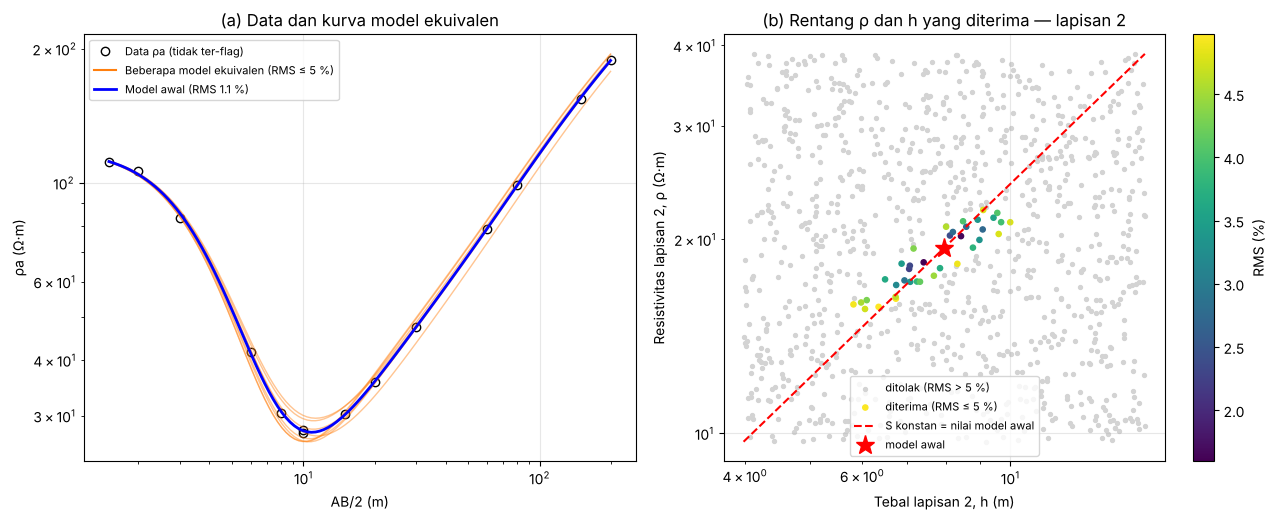

In [18]:
# ---- Prompt 5 (bagian 3): gambar ----
fig, axes = plt.subplots(1, 2, figsize=(13, 5.3))
ax = axes[0]
ax.loglog(s_obs, rho_obs, "ko", mfc="none", label="Data ρa (tidak ter-flag)")
sh = np.geomspace(s_obs.min(), s_obs.max(), 120)
terpilih = eq.sample(min(8, len(eq)), random_state=1) if len(eq) else eq
for _, r in terpilih.iterrows():
    r2, h2 = rho5.copy(), h5.copy(); r2[int(r["lapisan"]) - 1] = r["rho (ohm.m)"]; h2[int(r["lapisan"]) - 1] = r["h (m)"]
    ax.loglog(sh, schlum_forward(r2, h2, sh), "-", color="tab:orange", alpha=0.45, lw=1)
ax.loglog([], [], "-", color="tab:orange", label="Beberapa model ekuivalen (RMS ≤ 5 %)")
ax.loglog(sh, schlum_forward(rho5, h5, sh), "b-", lw=2, label=f"Model awal (RMS {rms0:.1f} %)")
ax.set_xlabel("AB/2 (m)"); ax.set_ylabel("ρa (Ω·m)"); ax.set_title("(a) Data dan kurva model ekuivalen"); ax.legend(fontsize=8)
ax = axes[1]
if keluarga:
    (i, jenis) = list(keluarga.keys())[0]
    a_ = acak[(i, jenis)]
    ok_ = a_[:, 2] <= TOL_RMS
    ax.scatter(a_[~ok_, 1], a_[~ok_, 0], s=8, color="lightgray", label="ditolak (RMS > 5 %)")
    sc = ax.scatter(a_[ok_, 1], a_[ok_, 0], s=14, c=a_[ok_, 2], cmap="viridis", label="diterima (RMS ≤ 5 %)")
    plt.colorbar(sc, ax=ax, label="RMS (%)")
    hh = np.geomspace(h5[i]*0.5, h5[i]*2, 100)
    ref = S_i[i] if jenis == "S" else T_i[i]
    ax.plot(hh, hh/ref if jenis == "S" else ref/hh, "r--", label=f"{jenis} konstan = nilai model awal")
    ax.plot(h5[i], rho5[i], "r*", ms=14, label="model awal")
    ax.set_xscale("log"); ax.set_yscale("log")
    ax.set_xlabel(f"Tebal lapisan {i+1}, h (m)"); ax.set_ylabel(f"Resistivitas lapisan {i+1}, ρ (Ω·m)")
    ax.set_title(f"(b) Rentang ρ dan h yang diterima — lapisan {i+1}"); ax.legend(fontsize=8)
else:
    ax.text(0.5, 0.5, "Tidak ada lapisan konduktif/resistif yang diuji", ha="center"); ax.axis("off")
plt.tight_layout(); plt.show()

### Interpretasi Prompt 5: parameter yang andal dan yang tidak

**Hasil hitungan.** Lapisan konduktif (lapisan 2, ρ ≈ 19 Ω·m, h ≈ 8 m) memiliki konduktansi longitudinal S ≈ 0,41 S. Model yang masih cocok dengan data (RMS ≤ 5 %) memiliki ρ ≈ 15,6–22,3 Ω·m dan h ≈ 5,8–10,0 m, atau sekitar ±20–25 % dari nilai awal, sedangkan S berada pada ≈ 0,37–0,47 S. Titik-titik diterima membentang sepanjang kurva S = konstan pada grafik (b): ρ dan h tidak dapat dipisahkan dengan baik, tetapi **rasio h/ρ (yaitu S) lebih tertentu**. Itulah isi prinsip ekuivalensi untuk lapisan konduktif.

**Parameter yang andal dan tidak.** Andal: S lapisan konduktif, serta ρ dan h lapisan 1 (tidak diuji tetapi dekat permukaan dan dikendalikan data AB/2 kecil). Kurang andal: ρ dan h lapisan 2 secara terpisah; parameter lapisan 3 dan kedalaman puncak lapisan 4 (model 3 lapisan memberi tebal total lapisan terbatas ≈ 14 m, sedangkan model 4 lapisan ≈ 35 m, walaupun S total kedua model hanya berbeda ≈ 17 %). Dampak pada geologi: ketebalan lapisan lempung atau kedalaman batuan dasar sebaiknya dilaporkan sebagai **rentang**, bukan satu angka.

**Keterbatasan.** Hanya 14 data dengan AB/2 maksimum 200 m dipakai, sehingga uji ekuivalensi untuk lapisan dalam tidak dilakukan (lapisan 3 bukan lapisan konduktif maupun resistif terhadap tetangganya, dan lapisan 4 adalah setengah ruang). Rentang yang dilaporkan bergantung pada toleransi 5 % dan pada anggapan bahwa lapisan lain tetap; rentang akan melebar bila noise lebih besar atau sebaran AB/2 lebih sempit.

**Kesimpulan.** Hasil VES paling aman dilaporkan melalui parameter gabungan (S, T) dan rentang ρ–h, bukan sebagai model tunggal yang "benar".

In [19]:
# ---- Ringkasan seluruh pemeriksaan (V) ----
ringkas = pd.DataFrame(CHECKS, columns=["Prompt", "Pemeriksaan", "Lulus", "Keterangan"])
ringkas["Prompt"] = ringkas["Prompt"].replace({"P0": "Fungsi forward", "P1": "Prompt 1", "P2": "Prompt 2", "P3": "Prompt 3", "P4": "Prompt 4", "P5": "Prompt 5"})
ringkas["Lulus"] = ringkas["Lulus"].map({True: "lulus", False: "GAGAL"})
display(ringkas[["Prompt", "Pemeriksaan", "Lulus"]])
print(f"Total pemeriksaan: {len(ringkas)}; lulus: {(ringkas['Lulus'] == 'lulus').sum()}; gagal: {(ringkas['Lulus'] == 'GAGAL').sum()}")
print("Pemeriksaan yang gagal tidak disembunyikan: dampaknya dijelaskan pada interpretasi prompt terkait (Prompt 4: keyakinan akuifer diturunkan).")

,Prompt,Pemeriksaan,Lulus
0,Fungsi forward,Forward: setengah ruang homogen 75 Ω·m menghasilkan ρa = 75 Ω·m,lulus
1,Fungsi forward,"Forward: dua lapisan (10/100 Ω·m, h = 0,5 m); AB/2 sangat kecil → ρ1 dan AB/2 besar → ρ2",lulus
2,Fungsi forward,Forward: tiga lapisan dengan ρ sama harus memberi ρa konstan,lulus
3,Prompt 1,Hitung ulang manual titik ke-8 cocok dengan program (selisih relatif < 1e-6),lulus
4,Prompt 1,"K Wenner (a = 10 m) = 62,83 m",lulus
5,Prompt 1,Jumlah baris keluaran = jumlah baris masukan,lulus
6,Prompt 1,Data ter-flag + tidak ter-flag = total,lulus
7,Prompt 1,Tidak ada ρa kosong atau tak hingga,lulus
8,Prompt 1,Setiap flag memiliki alasan,lulus
9,Prompt 2,Forward ulang dari model hasil inversi menghasilkan RMS yang sama dengan yang dilaporkan,lulus


Total pemeriksaan: 23; lulus: 22; gagal: 1
Pemeriksaan yang gagal tidak disembunyikan: dampaknya dijelaskan pada interpretasi prompt terkait (Prompt 4: keyakinan akuifer diturunkan).


## Kesimpulan Implementasi Kode

Kelima prompt R–T–C–I–K–O–Q–V telah diterjemahkan menjadi kode yang dapat dijalankan dari data mentah sampai interpretasi: (1) QC data dan perhitungan ρa dengan flag beralasan, (2) inversi VES 1D dengan perbandingan jumlah lapisan, (3) inversi ERT 2D dengan RMS per iterasi dan uji kestabilan, (4) korelasi model dengan data bor beserta tingkat keyakinan, dan (5) parameter Dar Zarrouk dengan uji ekuivalensi. Seluruh keluaran berasal dari **data sintetis**; interpretasi geologi di dalamnya adalah dugaan bersyarat, bukan temuan lapangan. Untuk laporan akhir, ganti data sintetis dengan data praktikum, sesuaikan ambang dan parameter, dan sitir sumber tabel resistivitas yang dipakai.